este notebook tiene dos bloques de codigo:
Paso 1. edad sobre datos depurados 
Paso 2. limpieza y depuracion del eda con observacion de experto

Cargando Excel...
Registros cargados: 60,693
Columnas originales: 79

EDA - CALIDAD Y DISTRIBUCIÓN DE DATOS
             Variable Tipo  Registros  No vacíos  Vacíos  % vacíos  Únicos No numéricos        Media    Mediana   Desv. est.        Mín       P25       P75         Máx
        Variedad_TIFF  Cat      60693      60693       0    0.0000      58                                                                                             
                Corte  Num      60693      60693       0    0.0000      33            0     5.306032        4.0     4.337781          1       2.0       7.0         100
                 Edad  Num      60693      60658      35    0.0577     712            0    12.477495      12.25     2.356969        0.1      11.4     13.34        72.8
                 Rdto  Num      60693      57295    3398    5.5987   34550            0    10.086455    10.2816     1.923062        0.0    9.2972   11.1942     16.3071
                  TAH  Num      60693      57449    

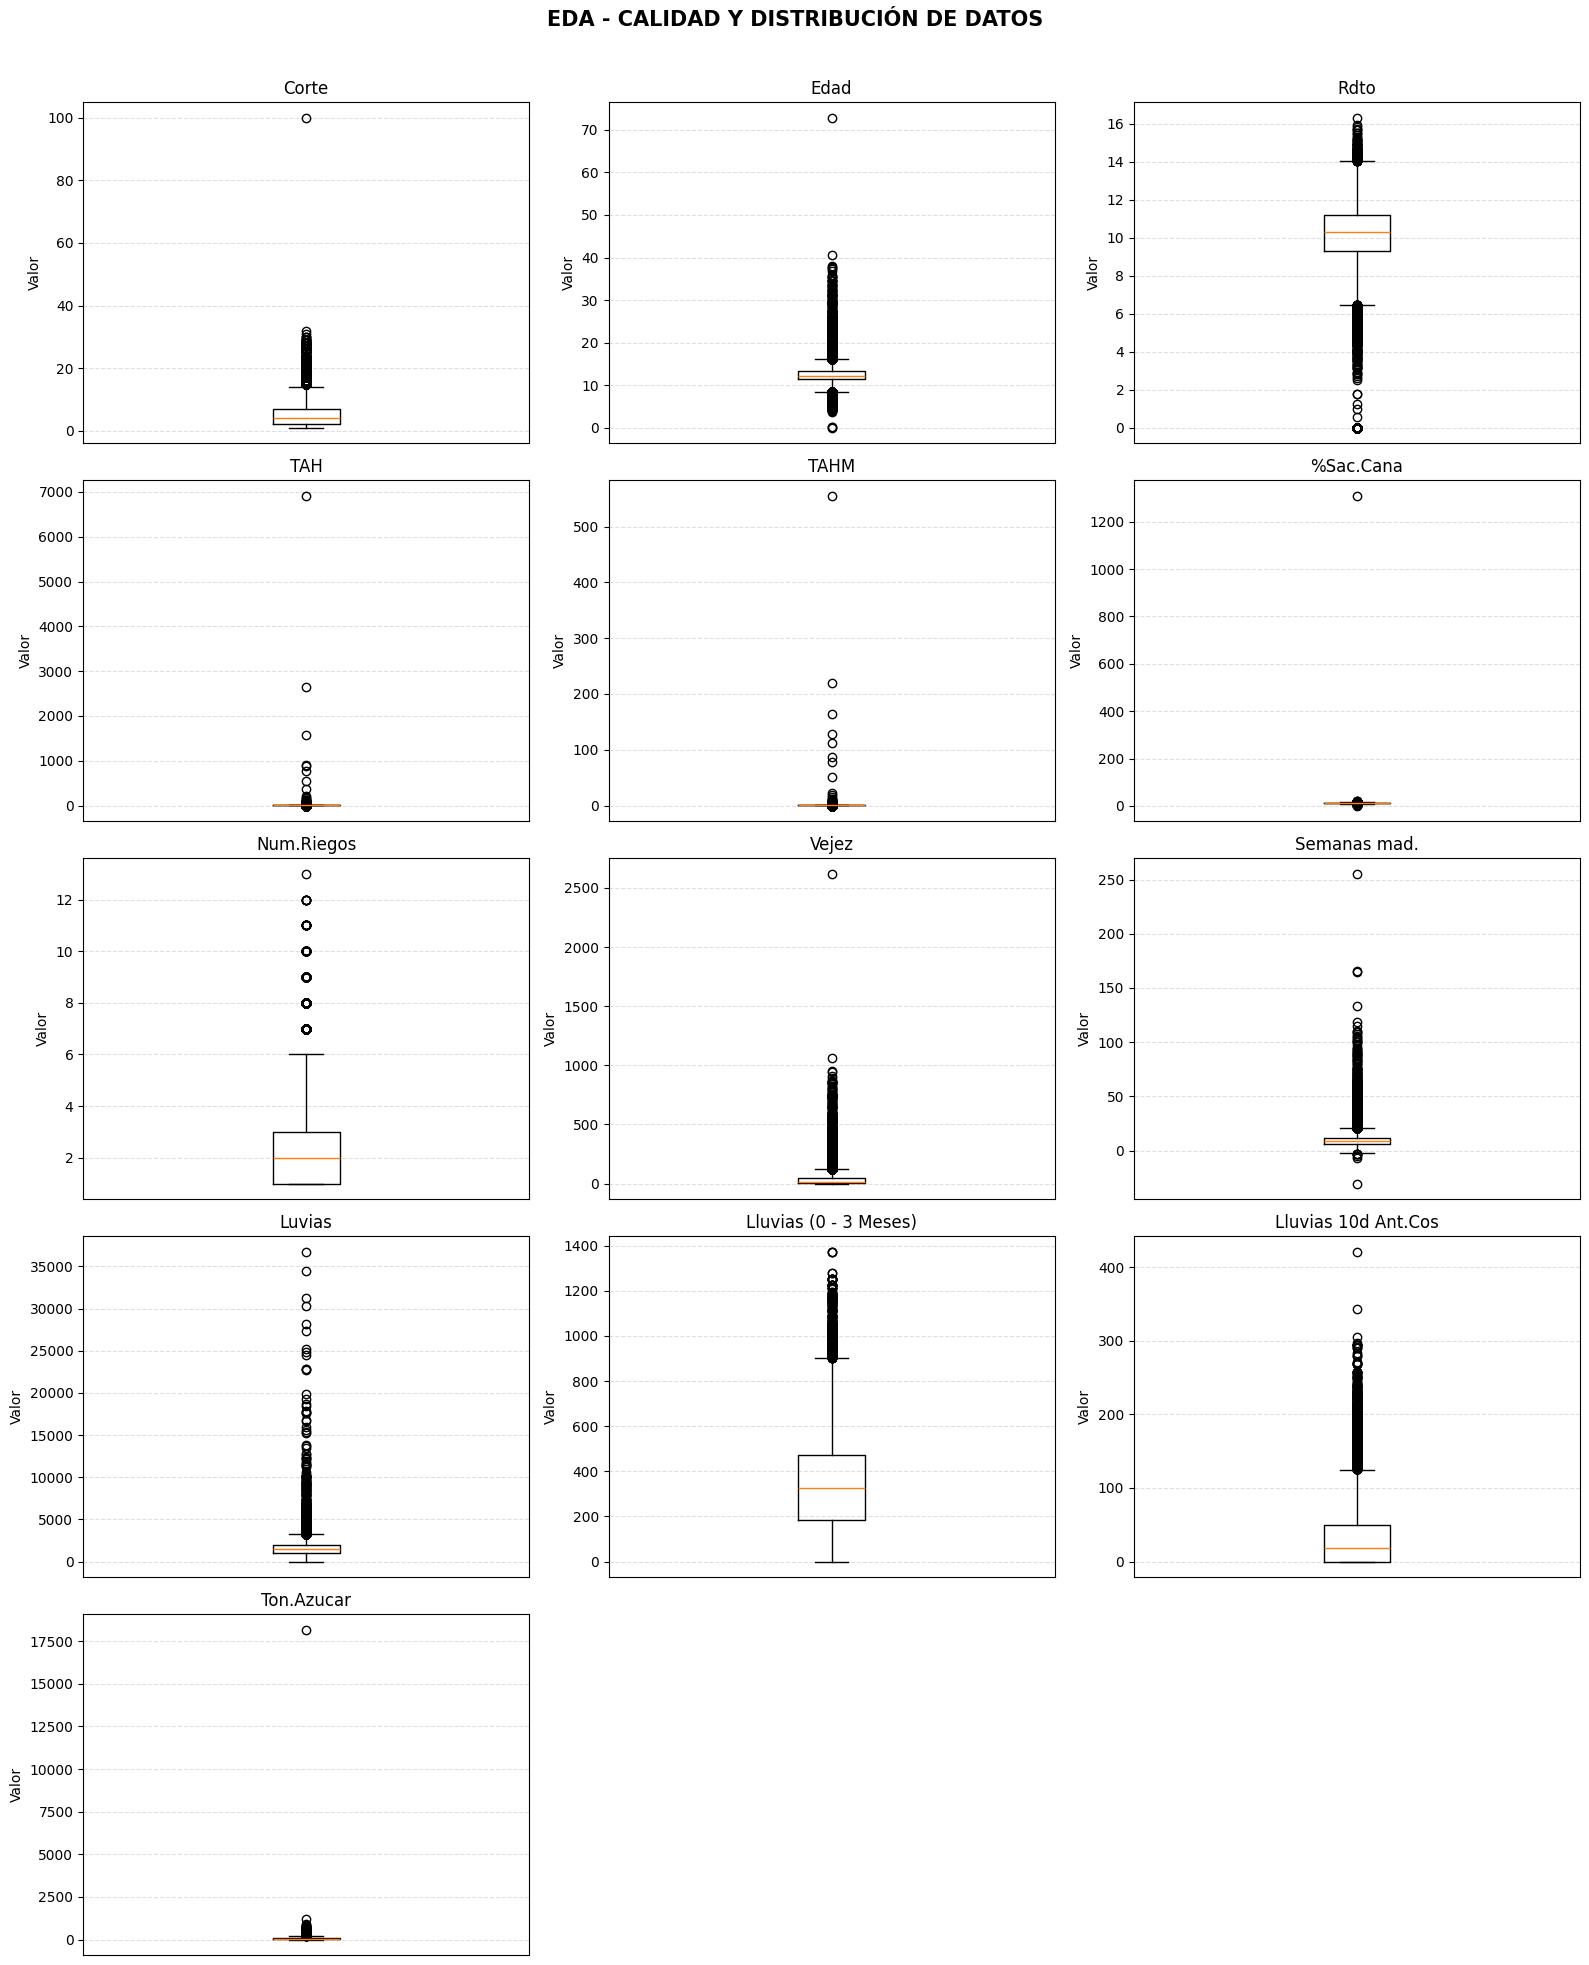


LÍMITES IQR Y VALORES CANDIDATOS A OUTLIERS
             Variable  Mín observado        Q1        Q3      IQR  Límite inferior IQR  Límite superior IQR  Candidatos inferiores  Candidatos superiores  Candidatos totales
                Corte         1.0000    2.0000    7.0000   5.0000              -5.5000              14.5000                      0                   3140                3140
                 Edad         0.1000   11.4000   13.3400   1.9400               8.4900              16.2500                   2268                   3285                5553
                 Rdto         0.0000    9.2972   11.1942   1.8970               6.4517              14.0397                   1519                    166                1685
                  TAH         0.0000    8.6525   13.4250   4.7725               1.4937              20.5838                    979                    582                1561
                 TAHM         0.0000    0.7087    1.0724   0.3636               0.163

In [ ]:
# Paso 1:
##############################
import os
import math
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

ARCHIVO_EXCEL = r"C:\Users\jjruiz\OneDrive - Sector Agro\Geodata\Analisis datos a raster\TEMP\depurados\Reporte_Biosal.xlsx"
HOJA_EXCEL = "Data_original"

FACTOR_IQR = 1.5

VARIABLES_EDA = [
    "Variedad_TIFF",
    "Corte",
    "Edad",
    "Rdto",
    "TAH",
    "TAHM",
    "%Sac.Cana",
    "Num.Riegos",
    "Vejez",
    "Semanas mad.",
    "Luvias",
    "Lluvias (0 - 3 Meses)",
    "Lluvias 10d Ant.Cos",
    "Ton.Azucar",
]

# Variedad_TIFF es categórica y no se evalúa con IQR.
VARIABLES_IQR = [
    col for col in VARIABLES_EDA
    if col != "Variedad_TIFF"
]

COLUMNAS_TEXTO = [
    "Llave",
    "Periodos",
    "Archivo_origen",
    "Periodo",
    "CODSIA",
    "Hacienda",
    "Suerte",
    "Poligono",
    "Capa_producto_final",
    "Nombre",
    "Zona",
    "G.Tenencia",
    "Tenencia",
]


# ============================================================
# 2. FUNCIONES AUXILIARES
# ============================================================

def convertir_analisis_numerico(serie):
    """
    Convierte temporalmente una serie a valores numéricos.
    No modifica la columna original del DataFrame.
    """
    return pd.to_numeric(serie, errors="coerce")


def calcular_eda(df):
    """
    Calcula estadísticas descriptivas para cada variable.
    Variedad_TIFF se trata como categórica.
    """
    resultados = []
    total = len(df)

    for col in VARIABLES_EDA:

        serie_original = df[col]

        no_vacios = int(serie_original.notna().sum())
        vacios = int(serie_original.isna().sum())

        if col == "Variedad_TIFF":

            valores = serie_original.dropna()

            resultados.append({
                "Variable": col,
                "Tipo": "Cat",
                "Registros": total,
                "No vacíos": no_vacios,
                "Vacíos": vacios,
                "% vacíos": (
                    vacios / total * 100 if total else 0
                ),
                "Únicos": valores.nunique(),
                "No numéricos": "",
                "Media": "",
                "Mediana": "",
                "Desv. est.": "",
                "Mín": "",
                "P25": "",
                "P75": "",
                "Máx": "",
            })

            continue

        numerica = convertir_analisis_numerico(
            serie_original
        )

        no_numericos = int(
            (
                serie_original.notna()
                & numerica.isna()
            ).sum()
        )

        valores = numerica.dropna()

        if valores.empty:

            media = mediana = desviacion = None
            minimo = p25 = p75 = maximo = None
            unicos = 0

        else:

            media = valores.mean()
            mediana = valores.median()
            desviacion = valores.std()
            minimo = valores.min()
            p25 = valores.quantile(0.25)
            p75 = valores.quantile(0.75)
            maximo = valores.max()
            unicos = valores.nunique()

        resultados.append({
            "Variable": col,
            "Tipo": "Num",
            "Registros": total,
            "No vacíos": no_vacios,
            "Vacíos": vacios,
            "% vacíos": (
                vacios / total * 100 if total else 0
            ),
            "Únicos": unicos,
            "No numéricos": no_numericos,
            "Media": media,
            "Mediana": mediana,
            "Desv. est.": desviacion,
            "Mín": minimo,
            "P25": p25,
            "P75": p75,
            "Máx": maximo,
        })

    return pd.DataFrame(resultados)


def mostrar_eda(df, titulo):
    """
    Presenta la tabla EDA y los diagramas de caja y bigotes.
    No elimina ni modifica registros.
    """

    eda = calcular_eda(df)

    print("\n" + "=" * 110)
    print(titulo)
    print("=" * 110)

    with pd.option_context(
        "display.max_columns", None,
        "display.width", 240,
        "display.max_rows", None
    ):
        print(
            eda.round(4).to_string(index=False)
        )

    # --------------------------------------------------------
    # Diagramas de caja y bigotes
    # --------------------------------------------------------

    n = len(VARIABLES_IQR)
    columnas = 3
    filas = math.ceil(n / columnas)

    fig, axes = plt.subplots(
        filas,
        columnas,
        figsize=(16, 4 * filas)
    )

    axes = axes.flatten()

    for i, col in enumerate(VARIABLES_IQR):

        valores = convertir_analisis_numerico(
            df[col]
        ).dropna()

        if valores.empty:
            axes[i].set_title(f"{col} - Sin datos numéricos")
            axes[i].set_visible(True)
            continue

        axes[i].boxplot(
            valores,
            whis=FACTOR_IQR,
            showfliers=True
        )

        axes[i].set_title(col)
        axes[i].set_ylabel("Valor")
        axes[i].set_xticks([])

        axes[i].grid(
            axis="y",
            linestyle="--",
            alpha=0.4
        )

    for i in range(n, len(axes)):
        axes[i].set_visible(False)

    fig.suptitle(
        titulo,
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.97]
    )

    plt.show()

    return eda


def calcular_limites_iqr(df):
    """
    Calcula los límites estadísticos IQR y cuenta
    los valores que quedan fuera de ellos.

    No elimina ni modifica ningún registro.
    """

    resultados = []

    for col in VARIABLES_IQR:

        valores = convertir_analisis_numerico(
            df[col]
        ).dropna()

        if valores.empty:

            resultados.append({
                "Variable": col,
                "Mín observado": None,
                "Q1": None,
                "Q3": None,
                "IQR": None,
                "Límite inferior IQR": None,
                "Límite superior IQR": None,
                "Candidatos inferiores": 0,
                "Candidatos superiores": 0,
                "Candidatos totales": 0,
            })

            continue

        q1 = valores.quantile(0.25)
        q3 = valores.quantile(0.75)

        iqr = q3 - q1

        limite_inf = q1 - FACTOR_IQR * iqr
        limite_sup = q3 + FACTOR_IQR * iqr

        n_inf = int(
            (valores < limite_inf).sum()
        )

        n_sup = int(
            (valores > limite_sup).sum()
        )

        resultados.append({
            "Variable": col,
            "Mín observado": valores.min(),
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Límite inferior IQR": limite_inf,
            "Límite superior IQR": limite_sup,
            "Candidatos inferiores": n_inf,
            "Candidatos superiores": n_sup,
            "Candidatos totales": n_inf + n_sup,
        })

    return pd.DataFrame(resultados)


# ============================================================
# 3. CARGAR EL EXCEL
# ============================================================

if not os.path.exists(ARCHIVO_EXCEL):
    raise FileNotFoundError(
        f"No se encontró el archivo:\n{ARCHIVO_EXCEL}"
    )

print("Cargando Excel...")

df = pd.read_excel(
    ARCHIVO_EXCEL,
    sheet_name=HOJA_EXCEL,
    dtype={
        col: "string"
        for col in COLUMNAS_TEXTO
    }
)

columnas_faltantes = [
    col for col in VARIABLES_EDA
    if col not in df.columns
]

if columnas_faltantes:
    raise ValueError(
        "Faltan variables requeridas en el Excel:\n"
        + "\n".join(columnas_faltantes)
    )

print(f"Registros cargados: {len(df):,}")
print(f"Columnas originales: {len(df.columns)}")


# ============================================================
# 4. EDA: TABLA Y GRÁFICOS
# ============================================================

eda = mostrar_eda(
    df,
    "EDA - CALIDAD Y DISTRIBUCIÓN DE DATOS"
)


# ============================================================
# 5. TABLA DE LÍMITES IQR Y CANDIDATOS A OUTLIERS
# ============================================================

tabla_iqr = calcular_limites_iqr(df)

print("\n" + "=" * 110)
print("LÍMITES IQR Y VALORES CANDIDATOS A OUTLIERS")
print("=" * 110)

with pd.option_context(
    "display.max_columns", None,
    "display.width", 240,
    "display.max_rows", None
):
    print(
        tabla_iqr.round(4).to_string(index=False)
    )

print("\nAnálisis terminado.")
print("No se eliminaron ni modificaron registros.")
print("El DataFrame original permanece disponible en la variable df.")


CONTROL DE CARGA DEL EXCEL ORIGINAL
Archivo: C:\Users\jjruiz\Downloads\Libro3.xlsx
Hoja: Data_Quemar
Registros originales: 53,116
Columnas originales: 79
Años encontrados: ['2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']

EDA ORIGINAL - ANTES DE APLICAR LOS RANGOS
             Variable Tipo  Registros  No vacíos  Vacíos  % vacíos  Únicos No numéricos        Media    Mediana  Desv. est.        Mín       P25        P75         Máx
        Variedad_TIFF  Cat      53116      53116       0    0.0000      13                                                                                             
                Corte  Num      53116      53116       0    0.0000      32            0     5.369851        4.0    4.378826          1       2.0        7.0         100
                 Edad  Num      53116      53088      28    0.0527     694            0    12.463878      12.25    2.298238        0.1     11.43      13.31        72.8
               

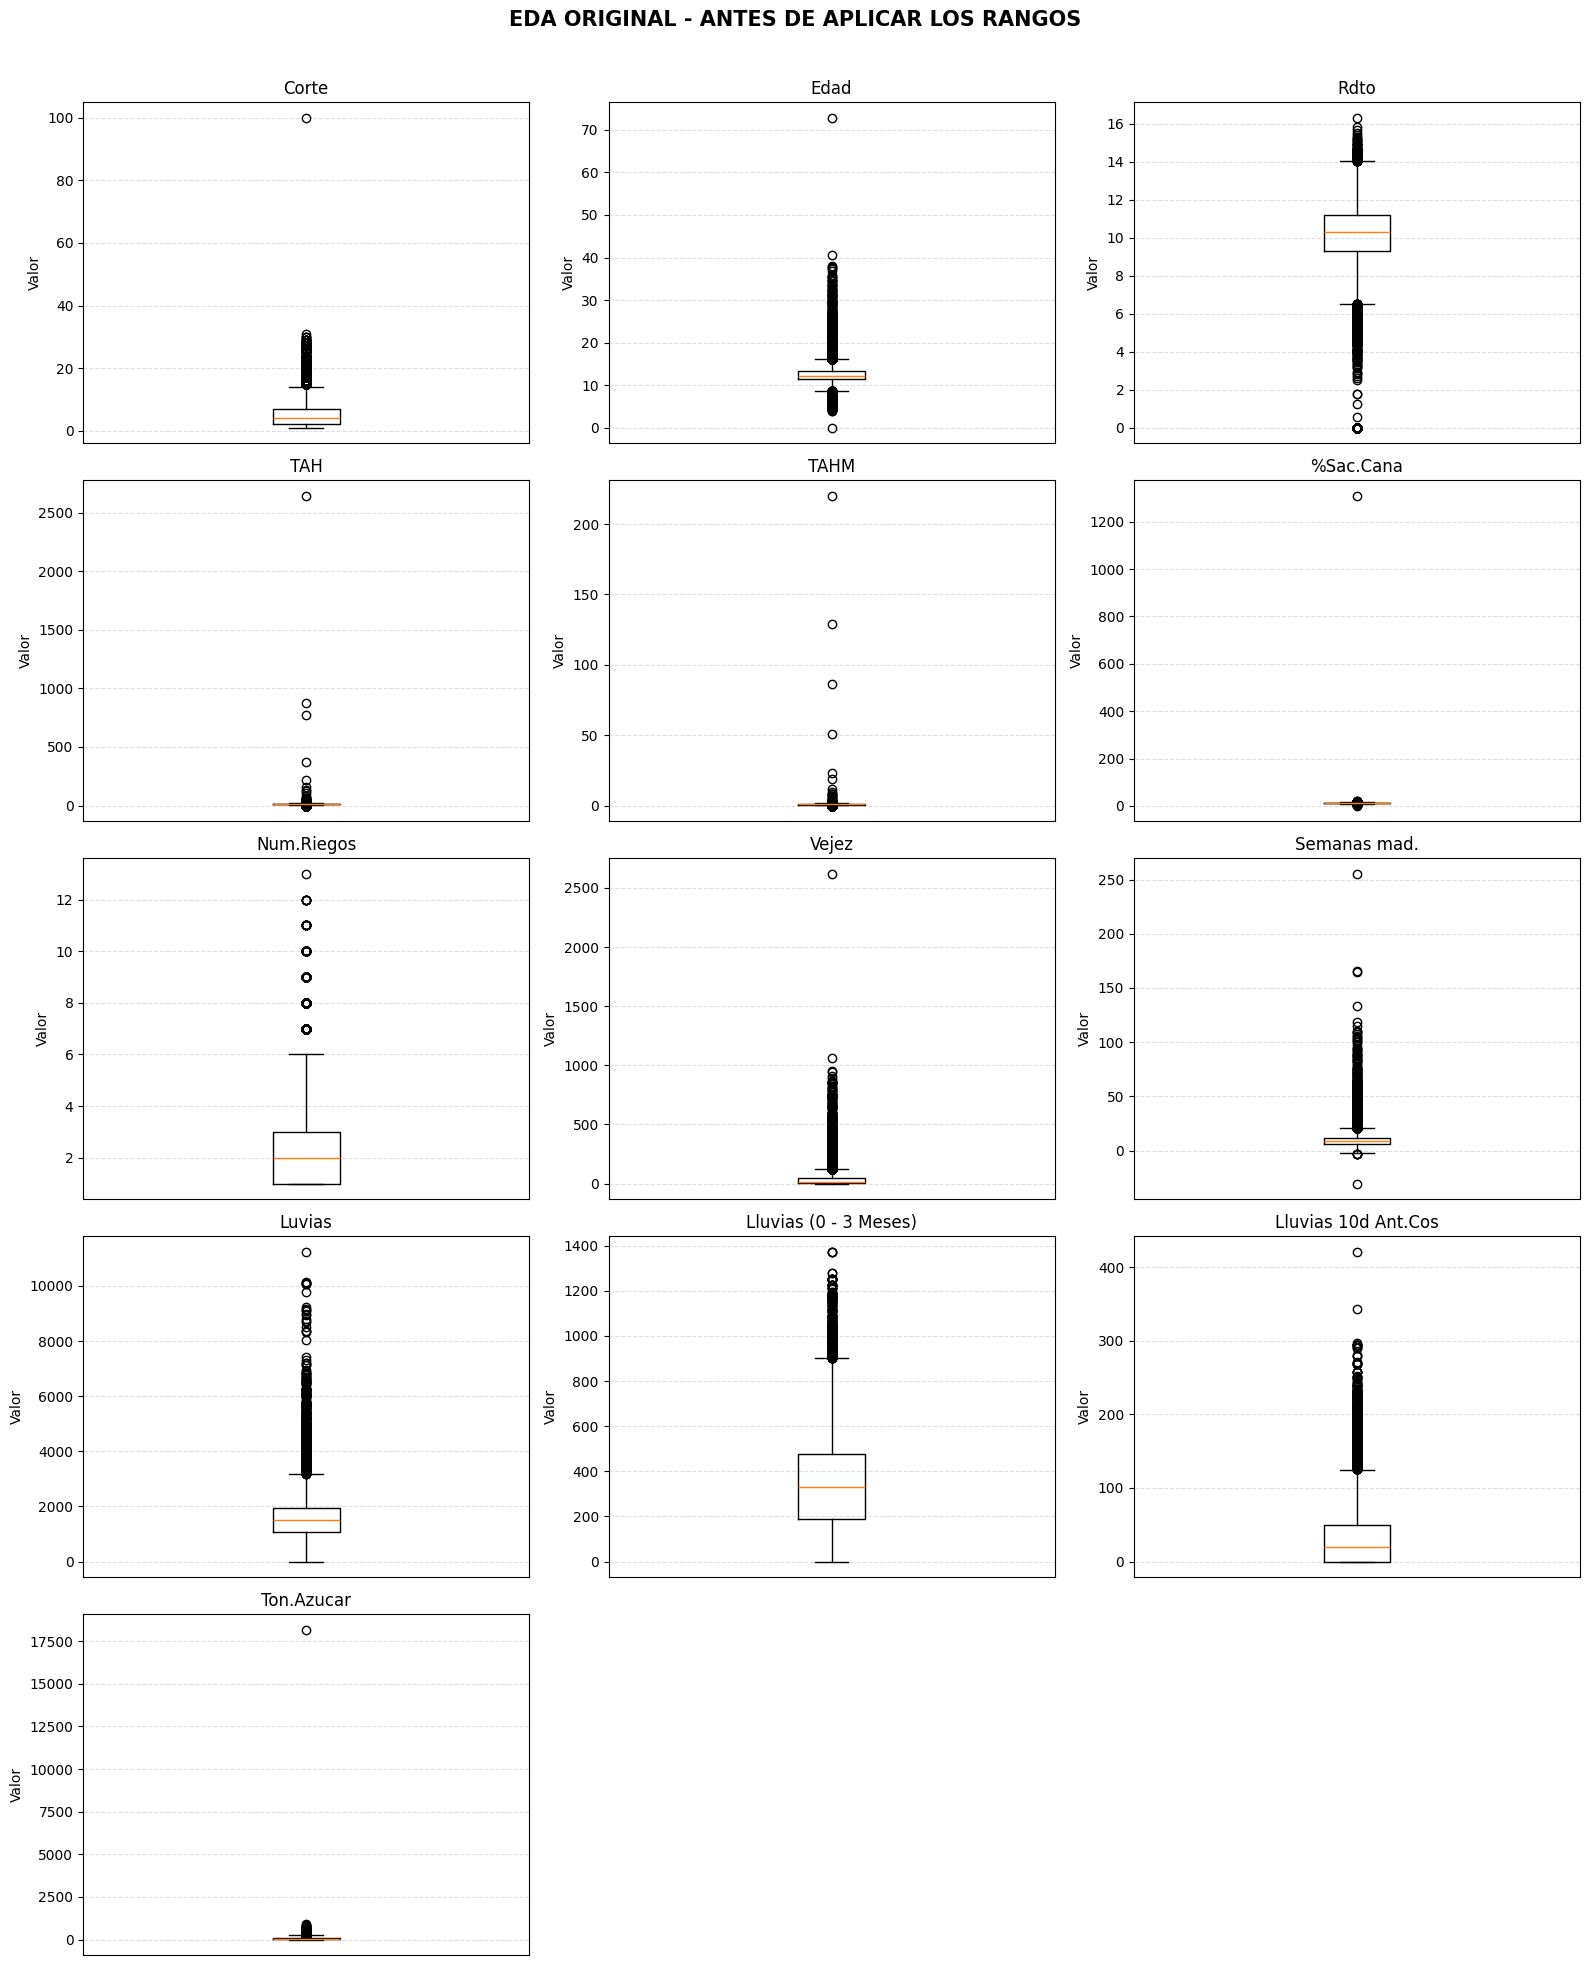


INCUMPLIMIENTOS POR VARIABLE EN EL ORIGINAL


,Variable,Minimo_permitido,Maximo_permitido,Minimo_observado,Maximo_observado,Valores_bajo_minimo,Valores_sobre_maximo,Total_fuera_rango_original
0,Corte,0,100,1.0000,100.0000,0,0,0
1,Edad,5,40,0.1000,72.8000,18,2,20
2,Rdto,3,17,0.0000,16.3071,808,0,808
3,TAH,0,100,0.0000,2644.8364,0,9,9
4,TAHM,0,10,0.0000,220.0363,0,7,7
5,%Sac.Cana,0,100,1.6060,1309.0000,0,1,1
6,Num.Riegos,0,14,1.0000,13.0000,0,0,0
7,Vejez,0,2700,0.0000,2619.8300,0,0,0
8,Semanas mad.,0,80,-30.2857,255.2857,25,38,63
9,Luvias,0,4500,0.0000,11239.0000,0,236,236


Registros originales: 53,116
Registros con al menos una variable fuera de rango: 1,138
Registros sin ninguna infracción de rango: 51,978

RESUMEN GENERAL DE DEPURACIÓN


,Registros_originales,Registros_finales,Registros_eliminados,Porcentaje_eliminado,Modo
0,53116,51978,1138,2.14,Eliminar filas completas



HISTORIAL POR VARIABLE


,Variable,Minimo,Maximo,Registros_antes,Valores_fuera_rango_en_este_paso,Filas_eliminadas_en_este_paso,Registros_despues
0,Corte,0,100,53116,0,0,53116
1,Edad,5,40,53116,20,20,53096
2,Rdto,3,17,53096,806,806,52290
3,TAH,0,100,52290,9,9,52281
4,TAHM,0,10,52281,0,0,52281
5,%Sac.Cana,0,100,52281,1,1,52280
6,Num.Riegos,0,14,52280,0,0,52280
7,Vejez,0,2700,52280,0,0,52280
8,Semanas mad.,0,80,52280,59,59,52221
9,Luvias,0,4500,52221,205,205,52016



REGISTROS POR AÑO: ORIGINAL VS DEPURADO


,year,Registros_antes,Registros_despues,Registros_eliminados,Porcentaje_eliminado
0,2014,4136,3994,142,3.43
1,2015,4913,4739,174,3.54
2,2016,5096,5084,12,0.24
3,2017,5059,5022,37,0.73
4,2018,5519,5447,72,1.30
5,2019,5003,4951,52,1.04
6,2020,4756,4698,58,1.22
7,2021,4237,4174,63,1.49
8,2022,4049,3823,226,5.58
9,2023,4117,3934,183,4.44


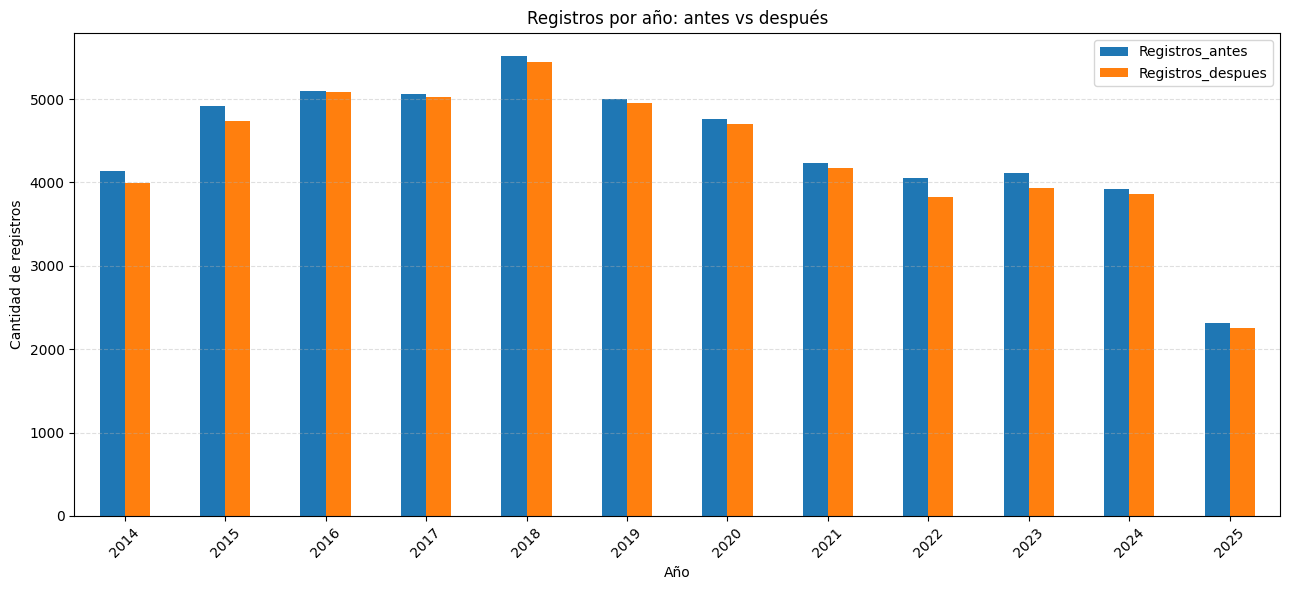


EDA FINAL - DESPUÉS DE APLICAR LOS NUEVOS RANGOS
             Variable Tipo  Registros  No vacíos  Vacíos  % vacíos  Únicos No numéricos        Media   Mediana  Desv. est.    Mín       P25        P75        Máx
        Variedad_TIFF  Cat      51978      51978       0    0.0000      13                                                                                       
                Corte  Num      51978      51978       0    0.0000      32            0      5.43655       4.0    4.390682      1       2.0        7.0        100
                 Edad  Num      51978      51952      26    0.0500     577            0    12.466614     12.25     2.06413   5.09      11.5      13.31      35.98
                 Rdto  Num      51978      51368     610    1.1736   32579            0    10.258304  10.31355    1.437897   3.16  9.369225    11.2119    16.3071
                  TAH  Num      51978      51496     482    0.9273   50576            0    11.234707  11.20243    3.616789    0.0  8.876389 

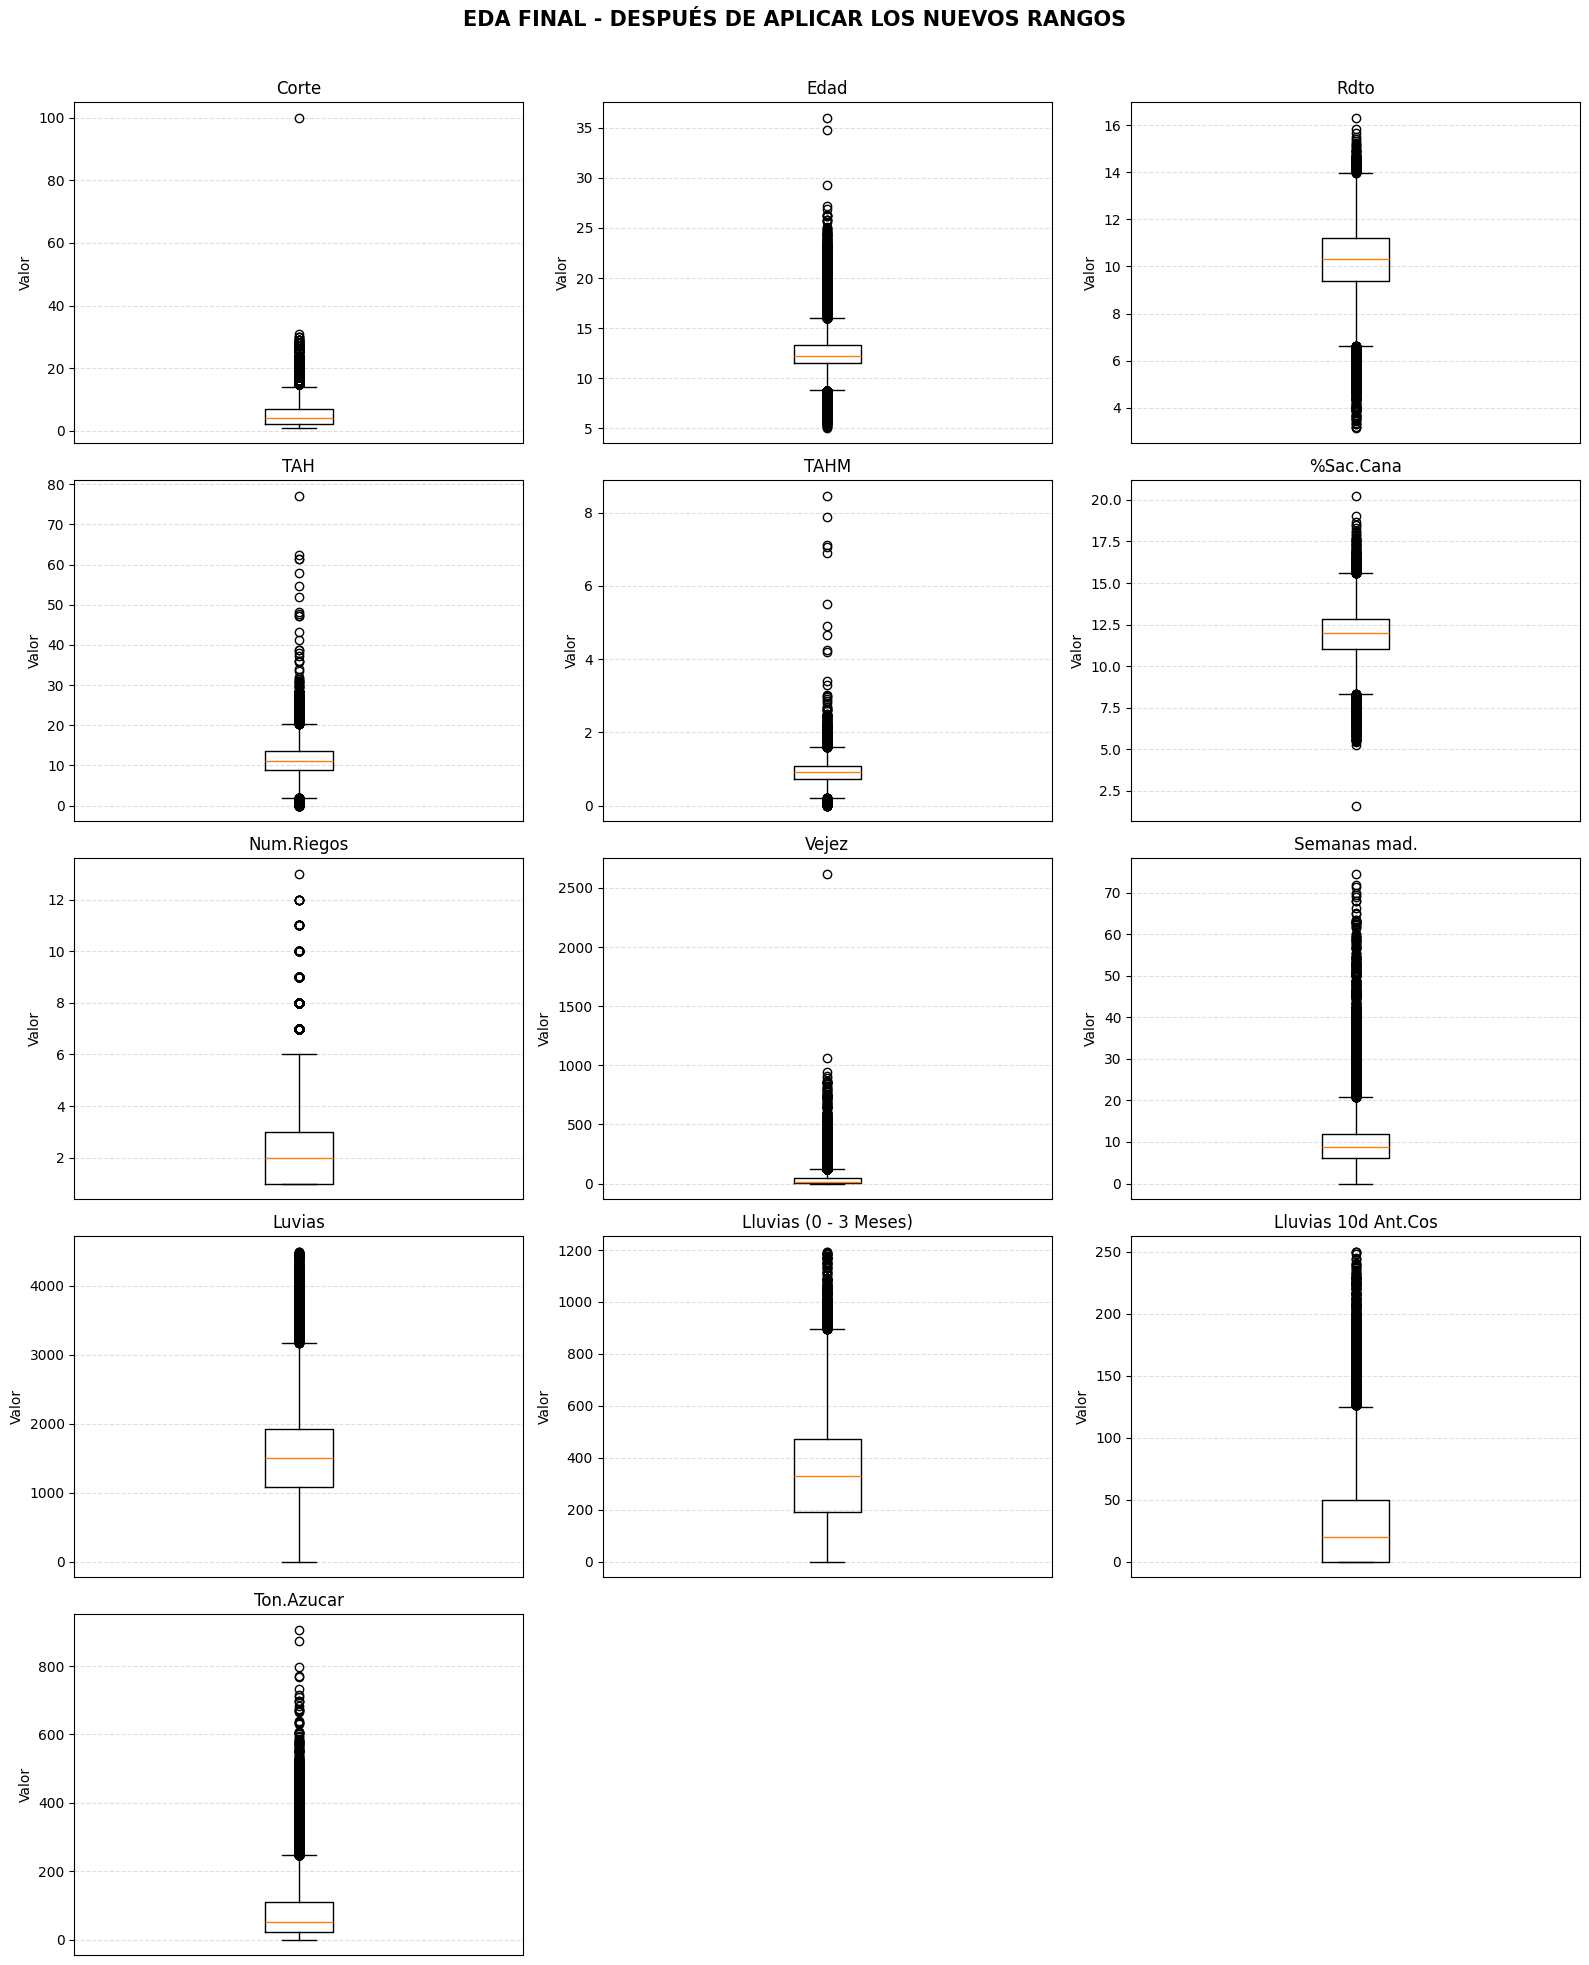


LÍMITES IQR DESPUÉS DE LA DEPURACIÓN


,Variable,Mín observado,Q1,Q3,IQR,Límite inferior IQR,Límite superior IQR,Candidatos inferiores,Candidatos superiores,Candidatos totales
0,Corte,1.000,2.0000,7.0000,5.0000,-5.5000,14.5000,0,2872,2872
1,Edad,5.090,11.5000,13.3100,1.8100,8.7850,16.0250,1868,2761,4629
2,Rdto,3.160,9.3692,11.2119,1.8427,6.6052,13.9759,621,160,781
3,TAH,0.000,8.8764,13.4742,4.5979,1.9796,20.3710,121,488,609
4,TAHM,0.000,0.7262,1.0755,0.3494,0.2021,1.5996,135,459,594
5,%Sac.Cana,1.606,11.0360,12.8612,1.8252,8.2982,15.5991,575,251,826
6,Num.Riegos,1.000,1.0000,3.0000,2.0000,-2.0000,6.0000,0,657,657
7,Vejez,0.000,2.1122,50.2652,48.1530,-70.1172,122.4947,0,2920,2920
8,Semanas mad.,0.000,6.1429,12.0000,5.8571,-2.6429,20.7857,0,1531,1531
9,Luvias,0.000,1077.5000,1915.0000,837.5000,-178.7500,3171.2500,0,746,746



COMPARACIÓN EDA: ORIGINAL VS DEPURADO


,Variable,Tipo_Antes,Registros_Antes,No vacíos_Antes,Vacíos_Antes,% vacíos_Antes,Únicos_Antes,No numéricos_Antes,Media_Antes,Mediana_Antes,...,% vacíos_Despues,Únicos_Despues,No numéricos_Despues,Media_Despues,Mediana_Despues,Desv. est._Despues,Mín_Despues,P25_Despues,P75_Despues,Máx_Despues
0,%Sac.Cana,Num,53116,51658,1458,2.7449,28424,0,11.946112,11.97,...,1.2351,28297,0,11.924778,11.9727,1.430569,1.606,11.036,12.861225,20.25
1,Corte,Num,53116,53116,0,0.0000,32,0,5.369851,4.0,...,0.0000,32,0,5.43655,4.0,4.390682,1,2.0,7.0,100
2,Edad,Num,53116,53088,28,0.0527,694,0,12.463878,12.25,...,0.0500,577,0,12.466614,12.25,2.06413,5.09,11.5,13.31,35.98
3,Lluvias (0 - 3 Meses),Num,53116,53116,0,0.0000,1063,0,338.344344,332.0,...,0.0000,1045,0,336.398719,330.0,209.591656,0.0,190.0,472.0,1193.0
4,Lluvias 10d Ant.Cos,Num,53116,53116,0,0.0000,261,0,32.81371,20.0,...,0.0000,243,0,32.430855,20.0,37.780944,0,0.0,50.0,250
5,Luvias,Num,53116,42246,10870,20.4646,3474,0,1503.530223,1500.0,...,19.5217,3267,0,1479.059497,1496.0,742.255679,0.0,1077.5,1915.0,4492.0
6,Num.Riegos,Num,53116,19052,34064,64.1313,13,0,2.658461,2.0,...,64.4234,13,0,2.656067,2.0,1.715574,1.0,1.0,3.0,13.0
7,Rdto,Num,53116,52488,628,1.1823,32737,0,10.097386,10.2851,...,1.1736,32579,0,10.258304,10.31355,1.437897,3.16,9.369225,11.2119,16.3071
8,Semanas mad.,Num,53116,23781,29335,55.2282,498,0,10.472123,8.714285,...,54.6712,402,0,10.132319,8.714285,7.108644,0.0,6.142857,12.0,74.571428
9,TAH,Num,53116,52624,492,0.9263,50896,0,11.15546,11.124886,...,0.9273,50576,0,11.234707,11.20243,3.616789,0.0,8.876389,13.47424,77.109523



COMPARACIÓN DE LÍMITES IQR


,Variable,Mín observado_Antes,Q1_Antes,Q3_Antes,IQR_Antes,Límite inferior IQR_Antes,Límite superior IQR_Antes,Candidatos inferiores_Antes,Candidatos superiores_Antes,Candidatos totales_Antes,Mín observado_Despues,Q1_Despues,Q3_Despues,IQR_Despues,Límite inferior IQR_Despues,Límite superior IQR_Despues,Candidatos inferiores_Despues,Candidatos superiores_Despues,Candidatos totales_Despues
0,%Sac.Cana,1.6060,11.0340,12.8589,1.8249,8.2967,15.5962,588,254,842,1.606,11.0360,12.8612,1.8252,8.2982,15.5991,575,251,826
1,Corte,1.0000,2.0000,7.0000,5.0000,-5.5000,14.5000,0,2878,2878,1.000,2.0000,7.0000,5.0000,-5.5000,14.5000,0,2872,2872
2,Edad,0.1000,11.4300,13.3100,1.8800,8.6100,16.1300,2006,2769,4775,5.090,11.5000,13.3100,1.8100,8.7850,16.0250,1868,2761,4629
3,Lluvias (0 - 3 Meses),0.0000,190.0000,475.0000,285.0000,-237.5000,902.5000,0,441,441,0.000,190.0000,472.0000,282.0000,-233.0000,895.0000,0,422,422
4,Lluvias 10d Ant.Cos,0.0000,0.0000,50.0000,50.0000,-75.0000,125.0000,0,1657,1657,0.000,0.0000,50.0000,50.0000,-75.0000,125.0000,0,1576,1576
5,Luvias,0.0000,1080.0000,1924.0000,844.0000,-186.0000,3190.0000,0,968,968,0.000,1077.5000,1915.0000,837.5000,-178.7500,3171.2500,0,746,746
6,Num.Riegos,1.0000,1.0000,3.0000,2.0000,-2.0000,6.0000,0,680,680,1.000,1.0000,3.0000,2.0000,-2.0000,6.0000,0,657,657
7,Rdto,0.0000,9.3132,11.1922,1.8790,6.4946,14.0107,1371,148,1519,3.160,9.3692,11.2119,1.8427,6.6052,13.9759,621,160,781
8,Semanas mad.,-30.2857,6.1429,12.0000,5.8571,-2.6429,20.7857,5,1678,1683,0.000,6.1429,12.0000,5.8571,-2.6429,20.7857,0,1531,1531
9,TAH,0.0000,8.7243,13.4328,4.7085,1.6616,20.4956,886,469,1355,0.000,8.8764,13.4742,4.5979,1.9796,20.3710,121,488,609


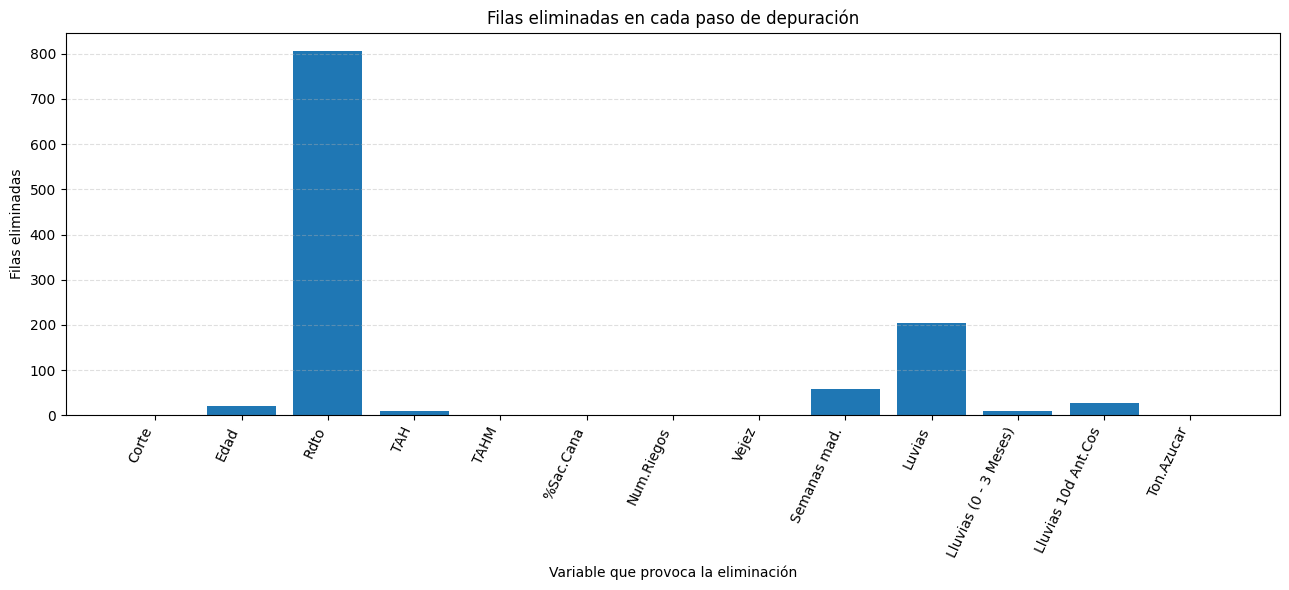


VERIFICACIONES FINALES
¿El original se conserva sin cambios?: True
¿La cantidad depurada coincide con el resumen?: True
Original: 53,116 registros
Depurado: 51,978 registros
Eliminados: 1,138 registros

DataFrames disponibles:
df_original_rangos          -> Excel original recargado
df_limpio_rangos            -> Datos depurados
df_resumen_rangos_original  -> Incumplimientos por variable
df_historial_rangos         -> Eliminación secuencial
df_eliminados_rangos        -> Filas eliminadas y causa
df_resumen_anios_rangos     -> Comparación por año
eda_comparativo_rangos      -> EDA antes y después
iqr_comparativo_rangos      -> IQR antes y después


In [ ]:
# Paso 2:
# ============================================================
# DEPURACIÓN ACTUALIZADA Y COMPARACIÓN REAL ANTES / DESPUÉS
# Ejecutar en una nueva celda del Notebook
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# ------------------------------------------------------------
# 1. CONFIGURACIÓN
# ------------------------------------------------------------

ARCHIVO_EXCEL = r"C:\Users\jjruiz\OneDrive - Sector Agro\Geodata\Analisis datos a raster\TEMP\depurados\Reporte_Biosal.xlsx"
HOJA_EXCEL = "Data_original"

RANGOS_DEPURACION = {
    "Corte": (0, 100),
    "Edad": (5, 40),
    "Rdto": (3, 17),
    "TAH": (0, 100),
    "TAHM": (0, 10),
    "%Sac.Cana": (0, 100),
    "Num.Riegos": (0, 14),
    "Vejez": (0, 2700),
    "Semanas mad.": (0, 80),
    "Luvias": (0, 4500),
    "Lluvias (0 - 3 Meses)": (0, 1200),
    "Lluvias 10d Ant.Cos": (0, 250),
    "Ton.Azucar": (0, 2300),
}

# True: eliminar la fila completa si alguna variable
# incumple su rango.
#
# False: conservar la fila y sustituir únicamente
# los valores fuera de rango por NaN.
ELIMINAR_FILAS_COMPLETAS = True


# ------------------------------------------------------------
# 2. CARGAR NUEVAMENTE EL EXCEL ORIGINAL
# ------------------------------------------------------------
# Importante: no reutilizamos df, porque pudo haber sido
# modificado en una celda ejecutada anteriormente.

if not os.path.exists(ARCHIVO_EXCEL):
    raise FileNotFoundError(
        f"No se encontró el archivo: {ARCHIVO_EXCEL}"
    )

COLUMNAS_TEXTO = [
    "Llave",
    "Periodos",
    "Archivo_origen",
    "Periodo",
    "CODSIA",
    "Hacienda",
    "Suerte",
    "Poligono",
    "Capa_producto_final",
    "Nombre",
    "Zona",
    "G.Tenencia",
    "Tenencia",
]

df_original_rangos = pd.read_excel(
    ARCHIVO_EXCEL,
    sheet_name=HOJA_EXCEL,
    dtype={
        col: "string"
        for col in COLUMNAS_TEXTO
    }
).reset_index(drop=True)

df_original_rangos.index.name = "Indice_original"

# Esta es la referencia inmutable para toda la comparación.
df_original_rangos = df_original_rangos.copy(deep=True)

columnas_faltantes = [
    col for col in RANGOS_DEPURACION
    if col not in df_original_rangos.columns
]

if columnas_faltantes:
    raise ValueError(
        "Faltan columnas en el Excel:\n"
        + "\n".join(columnas_faltantes)
    )

TOTAL_ORIGINAL = len(df_original_rangos)

print("=" * 90)
print("CONTROL DE CARGA DEL EXCEL ORIGINAL")
print("=" * 90)
print(f"Archivo: {ARCHIVO_EXCEL}")
print(f"Hoja: {HOJA_EXCEL}")
print(f"Registros originales: {TOTAL_ORIGINAL:,}")
print(f"Columnas originales: {len(df_original_rangos.columns)}")

if TOTAL_ORIGINAL == 0:
    raise ValueError("El Excel no contiene registros.")

if "year" in df_original_rangos.columns:
    print(
        "Años encontrados:",
        sorted(
            df_original_rangos["year"]
            .dropna()
            .astype(str)
            .unique()
            .tolist()
        )
    )


# ------------------------------------------------------------
# 3. EDA ORIGINAL
# ------------------------------------------------------------
# Utiliza las funciones calcular_eda(), mostrar_eda()
# y calcular_limites_iqr() definidas en la celda anterior.

eda_antes_rangos = mostrar_eda(
    df_original_rangos,
    "EDA ORIGINAL - ANTES DE APLICAR LOS RANGOS"
)

iqr_antes_rangos = calcular_limites_iqr(
    df_original_rangos
)


# ------------------------------------------------------------
# 4. CONTAR INCUMPLIMIENTOS EN EL ORIGINAL
# ------------------------------------------------------------
# Estos conteos se calculan sobre el Excel original.
# Un mismo registro puede incumplir varias variables.

mascaras_originales = {}
resumen_inicial = []

for variable, (minimo, maximo) in RANGOS_DEPURACION.items():

    valores = pd.to_numeric(
        df_original_rangos[variable],
        errors="coerce"
    )

    inferior = valores.notna() & (valores < minimo)
    superior = valores.notna() & (valores > maximo)
    fuera = inferior | superior

    mascaras_originales[variable] = fuera

    resumen_inicial.append({
        "Variable": variable,
        "Minimo_permitido": minimo,
        "Maximo_permitido": maximo,
        "Minimo_observado": valores.min(),
        "Maximo_observado": valores.max(),
        "Valores_bajo_minimo": int(inferior.sum()),
        "Valores_sobre_maximo": int(superior.sum()),
        "Total_fuera_rango_original": int(fuera.sum()),
    })

df_resumen_rangos_original = pd.DataFrame(resumen_inicial)

print("\n" + "=" * 90)
print("INCUMPLIMIENTOS POR VARIABLE EN EL ORIGINAL")
print("=" * 90)
display(df_resumen_rangos_original.round(4))


# ------------------------------------------------------------
# 5. IDENTIFICAR REGISTROS ÚNICOS QUE INCUMPLEN RANGOS
# ------------------------------------------------------------

mascara_cualquier_infraccion = pd.Series(
    False,
    index=df_original_rangos.index
)

for mascara in mascaras_originales.values():
    mascara_cualquier_infraccion |= mascara

registros_candidatos_unicos = int(
    mascara_cualquier_infraccion.sum()
)

print(f"Registros originales: {TOTAL_ORIGINAL:,}")
print(
    "Registros con al menos una variable fuera de rango: "
    f"{registros_candidatos_unicos:,}"
)
print(
    "Registros sin ninguna infracción de rango: "
    f"{TOTAL_ORIGINAL - registros_candidatos_unicos:,}"
)


# ------------------------------------------------------------
# 6. DEPURAR SOBRE UNA COPIA DEL ORIGINAL
# ------------------------------------------------------------

df_limpio_rangos = df_original_rangos.copy(deep=True)

historial_rangos = []
registros_eliminados_rangos = []

for variable, (minimo, maximo) in RANGOS_DEPURACION.items():

    cantidad_antes = len(df_limpio_rangos)

    valores = pd.to_numeric(
        df_limpio_rangos[variable],
        errors="coerce"
    )

    mascara = (
        valores.notna()
        & (
            (valores < minimo)
            | (valores > maximo)
        )
    )

    cantidad_fuera = int(mascara.sum())

    if ELIMINAR_FILAS_COMPLETAS:

        if cantidad_fuera > 0:
            eliminados = df_limpio_rangos.loc[
                mascara
            ].copy()

            eliminados["Variable_causante"] = variable
            eliminados["Valor_fuera_rango"] = valores.loc[
                mascara
            ].values
            eliminados["Minimo_permitido"] = minimo
            eliminados["Maximo_permitido"] = maximo

            registros_eliminados_rangos.append(eliminados)

            df_limpio_rangos = df_limpio_rangos.loc[
                ~mascara
            ].copy()

    else:
        # Solo se elimina el valor inválido de esa variable.
        # No se elimina la fila completa.
        df_limpio_rangos.loc[
            mascara, variable
        ] = float("nan")

    cantidad_despues = len(df_limpio_rangos)

    historial_rangos.append({
        "Variable": variable,
        "Minimo": minimo,
        "Maximo": maximo,
        "Registros_antes": cantidad_antes,
        "Valores_fuera_rango_en_este_paso": cantidad_fuera,
        "Filas_eliminadas_en_este_paso": (
            cantidad_antes - cantidad_despues
        ),
        "Registros_despues": cantidad_despues,
    })

df_historial_rangos = pd.DataFrame(historial_rangos)

if registros_eliminados_rangos:
    df_eliminados_rangos = pd.concat(
        registros_eliminados_rangos,
        ignore_index=True
    )
else:
    df_eliminados_rangos = pd.DataFrame()


# ------------------------------------------------------------
# 7. RESUMEN GENERAL: ORIGINAL VS DEPURADO
# ------------------------------------------------------------

TOTAL_FINAL = len(df_limpio_rangos)
TOTAL_ELIMINADO = TOTAL_ORIGINAL - TOTAL_FINAL

PORCENTAJE_ELIMINADO = (
    TOTAL_ELIMINADO / TOTAL_ORIGINAL * 100
)

df_resumen_general_rangos = pd.DataFrame([{
    "Registros_originales": TOTAL_ORIGINAL,
    "Registros_finales": TOTAL_FINAL,
    "Registros_eliminados": TOTAL_ELIMINADO,
    "Porcentaje_eliminado": PORCENTAJE_ELIMINADO,
    "Modo": (
        "Eliminar filas completas"
        if ELIMINAR_FILAS_COMPLETAS
        else "Reemplazar valores fuera de rango por NaN"
    )
}])

print("\n" + "=" * 90)
print("RESUMEN GENERAL DE DEPURACIÓN")
print("=" * 90)
display(df_resumen_general_rangos.round(2))

print("\nHISTORIAL POR VARIABLE")
display(df_historial_rangos)


# ------------------------------------------------------------
# 8. COMPARACIÓN REAL DE REGISTROS POR AÑO
# ------------------------------------------------------------

if "year" in df_original_rangos.columns:

    antes_anio = (
        df_original_rangos.groupby("year", dropna=False)
        .size()
        .rename("Registros_antes")
    )

    despues_anio = (
        df_limpio_rangos.groupby("year", dropna=False)
        .size()
        .rename("Registros_despues")
    )

    df_resumen_anios_rangos = pd.concat(
        [antes_anio, despues_anio],
        axis=1
    ).fillna(0)

    df_resumen_anios_rangos = (
        df_resumen_anios_rangos.astype(int)
        .reset_index()
    )

    df_resumen_anios_rangos["Registros_eliminados"] = (
        df_resumen_anios_rangos["Registros_antes"]
        - df_resumen_anios_rangos["Registros_despues"]
    )

    df_resumen_anios_rangos["Porcentaje_eliminado"] = (
        df_resumen_anios_rangos["Registros_eliminados"]
        / df_resumen_anios_rangos["Registros_antes"].replace(0, float("nan"))
        * 100
    ).fillna(0)

    print("\n" + "=" * 90)
    print("REGISTROS POR AÑO: ORIGINAL VS DEPURADO")
    print("=" * 90)
    display(df_resumen_anios_rangos.round(2))

    ax = df_resumen_anios_rangos.plot(
        x="year",
        y=["Registros_antes", "Registros_despues"],
        kind="bar",
        figsize=(13, 6)
    )

    ax.set_title("Registros por año: antes vs después")
    ax.set_xlabel("Año")
    ax.set_ylabel("Cantidad de registros")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

else:
    df_resumen_anios_rangos = pd.DataFrame()


# ------------------------------------------------------------
# 9. EDA FINAL Y COMPARACIÓN DE ESTADÍSTICAS
# ------------------------------------------------------------

eda_despues_rangos = mostrar_eda(
    df_limpio_rangos,
    "EDA FINAL - DESPUÉS DE APLICAR LOS NUEVOS RANGOS"
)

iqr_despues_rangos = calcular_limites_iqr(
    df_limpio_rangos
)

print("\nLÍMITES IQR DESPUÉS DE LA DEPURACIÓN")
display(iqr_despues_rangos.round(4))


# Comparación de todas las estadísticas.
eda_comparativo_rangos = eda_antes_rangos.merge(
    eda_despues_rangos,
    on="Variable",
    how="outer",
    suffixes=("_Antes", "_Despues")
)

print("\n" + "=" * 90)
print("COMPARACIÓN EDA: ORIGINAL VS DEPURADO")
print("=" * 90)
display(eda_comparativo_rangos.round(4))


# Comparación de límites IQR.
iqr_comparativo_rangos = iqr_antes_rangos.merge(
    iqr_despues_rangos,
    on="Variable",
    how="outer",
    suffixes=("_Antes", "_Despues")
)

print("\nCOMPARACIÓN DE LÍMITES IQR")
display(iqr_comparativo_rangos.round(4))


# ------------------------------------------------------------
# 10. GRÁFICO DE REGISTROS ELIMINADOS POR VARIABLE
# ------------------------------------------------------------

plt.figure(figsize=(13, 6))

plt.bar(
    df_historial_rangos["Variable"],
    df_historial_rangos["Filas_eliminadas_en_este_paso"]
)

plt.title("Filas eliminadas en cada paso de depuración")
plt.xlabel("Variable que provoca la eliminación")
plt.ylabel("Filas eliminadas")

plt.xticks(rotation=65, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. VERIFICACIONES FINALES
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("VERIFICACIONES FINALES")
print("=" * 90)

print(
    "¿El original se conserva sin cambios?:",
    len(df_original_rangos) == TOTAL_ORIGINAL
)

print(
    "¿La cantidad depurada coincide con el resumen?:",
    len(df_limpio_rangos) == TOTAL_FINAL
)

print(
    f"Original: {len(df_original_rangos):,} registros"
)
print(
    f"Depurado: {len(df_limpio_rangos):,} registros"
)
print(
    f"Eliminados: {TOTAL_ELIMINADO:,} registros"
)

print("\nDataFrames disponibles:")
print("df_original_rangos          -> Excel original recargado")
print("df_limpio_rangos            -> Datos depurados")
print("df_resumen_rangos_original  -> Incumplimientos por variable")
print("df_historial_rangos         -> Eliminación secuencial")
print("df_eliminados_rangos        -> Filas eliminadas y causa")
print("df_resumen_anios_rangos     -> Comparación por año")
print("eda_comparativo_rangos      -> EDA antes y después")
print("iqr_comparativo_rangos      -> IQR antes y después")


CARGA DEL EXCEL ORIGINAL
Archivo: C:\Users\jjruiz\Downloads\Libro3.xlsx
Hoja: Data_Quemar_original
Registros originales: 60,693
Columnas originales: 79
Años encontrados: ['2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', '2026']

EDA INICIAL - ANTES DE DEPURAR VALORES


,Variable,Tipo,Registros,No vacíos,Vacíos,% vacíos,Únicos,No numéricos,Media,Mediana,Desv. est.,Mín,P25,P75,Máx
0,Variedad_TIFF,Cat,60693,60693,0,0.0000,58,,,,,,,,
1,Corte,Num,60693,60693,0,0.0000,33,0,5.306032,4.0,4.337781,1,2.0,7.0,100
2,Edad,Num,60693,60658,35,0.0577,712,0,12.477495,12.25,2.356969,0.1,11.4,13.34,72.8
3,Rdto,Num,60693,59857,836,1.3774,35586,0,10.048478,10.2471,1.929506,0.0,9.2527,11.1661,16.3071
4,TAH,Num,60693,60023,670,1.1039,57618,0,11.283781,11.021015,33.204612,0.0,8.565722,13.367414,6914.675
5,TAHM,Num,60693,59992,701,1.1550,57203,0,0.912522,0.891831,2.827094,0.0,0.69958,1.067265,555.395582
6,%Sac.Cana,Num,60693,58898,1795,2.9575,30449,0,11.898347,11.9309,5.541621,1.606,10.972325,12.8355,1309.0
7,Num.Riegos,Num,60693,20718,39975,65.8643,13,0,2.621682,2.0,1.694862,1.0,1.0,3.0,13.0
8,Vejez,Num,60693,59412,1281,2.1106,30928,0,36.318338,9.117,61.728572,0.0,2.099,50.5775,2619.83
9,Semanas mad.,Num,60693,26491,34202,56.3525,511,0,10.672498,8.714285,8.938347,-30.285714,6.142857,12.285714,255.285714


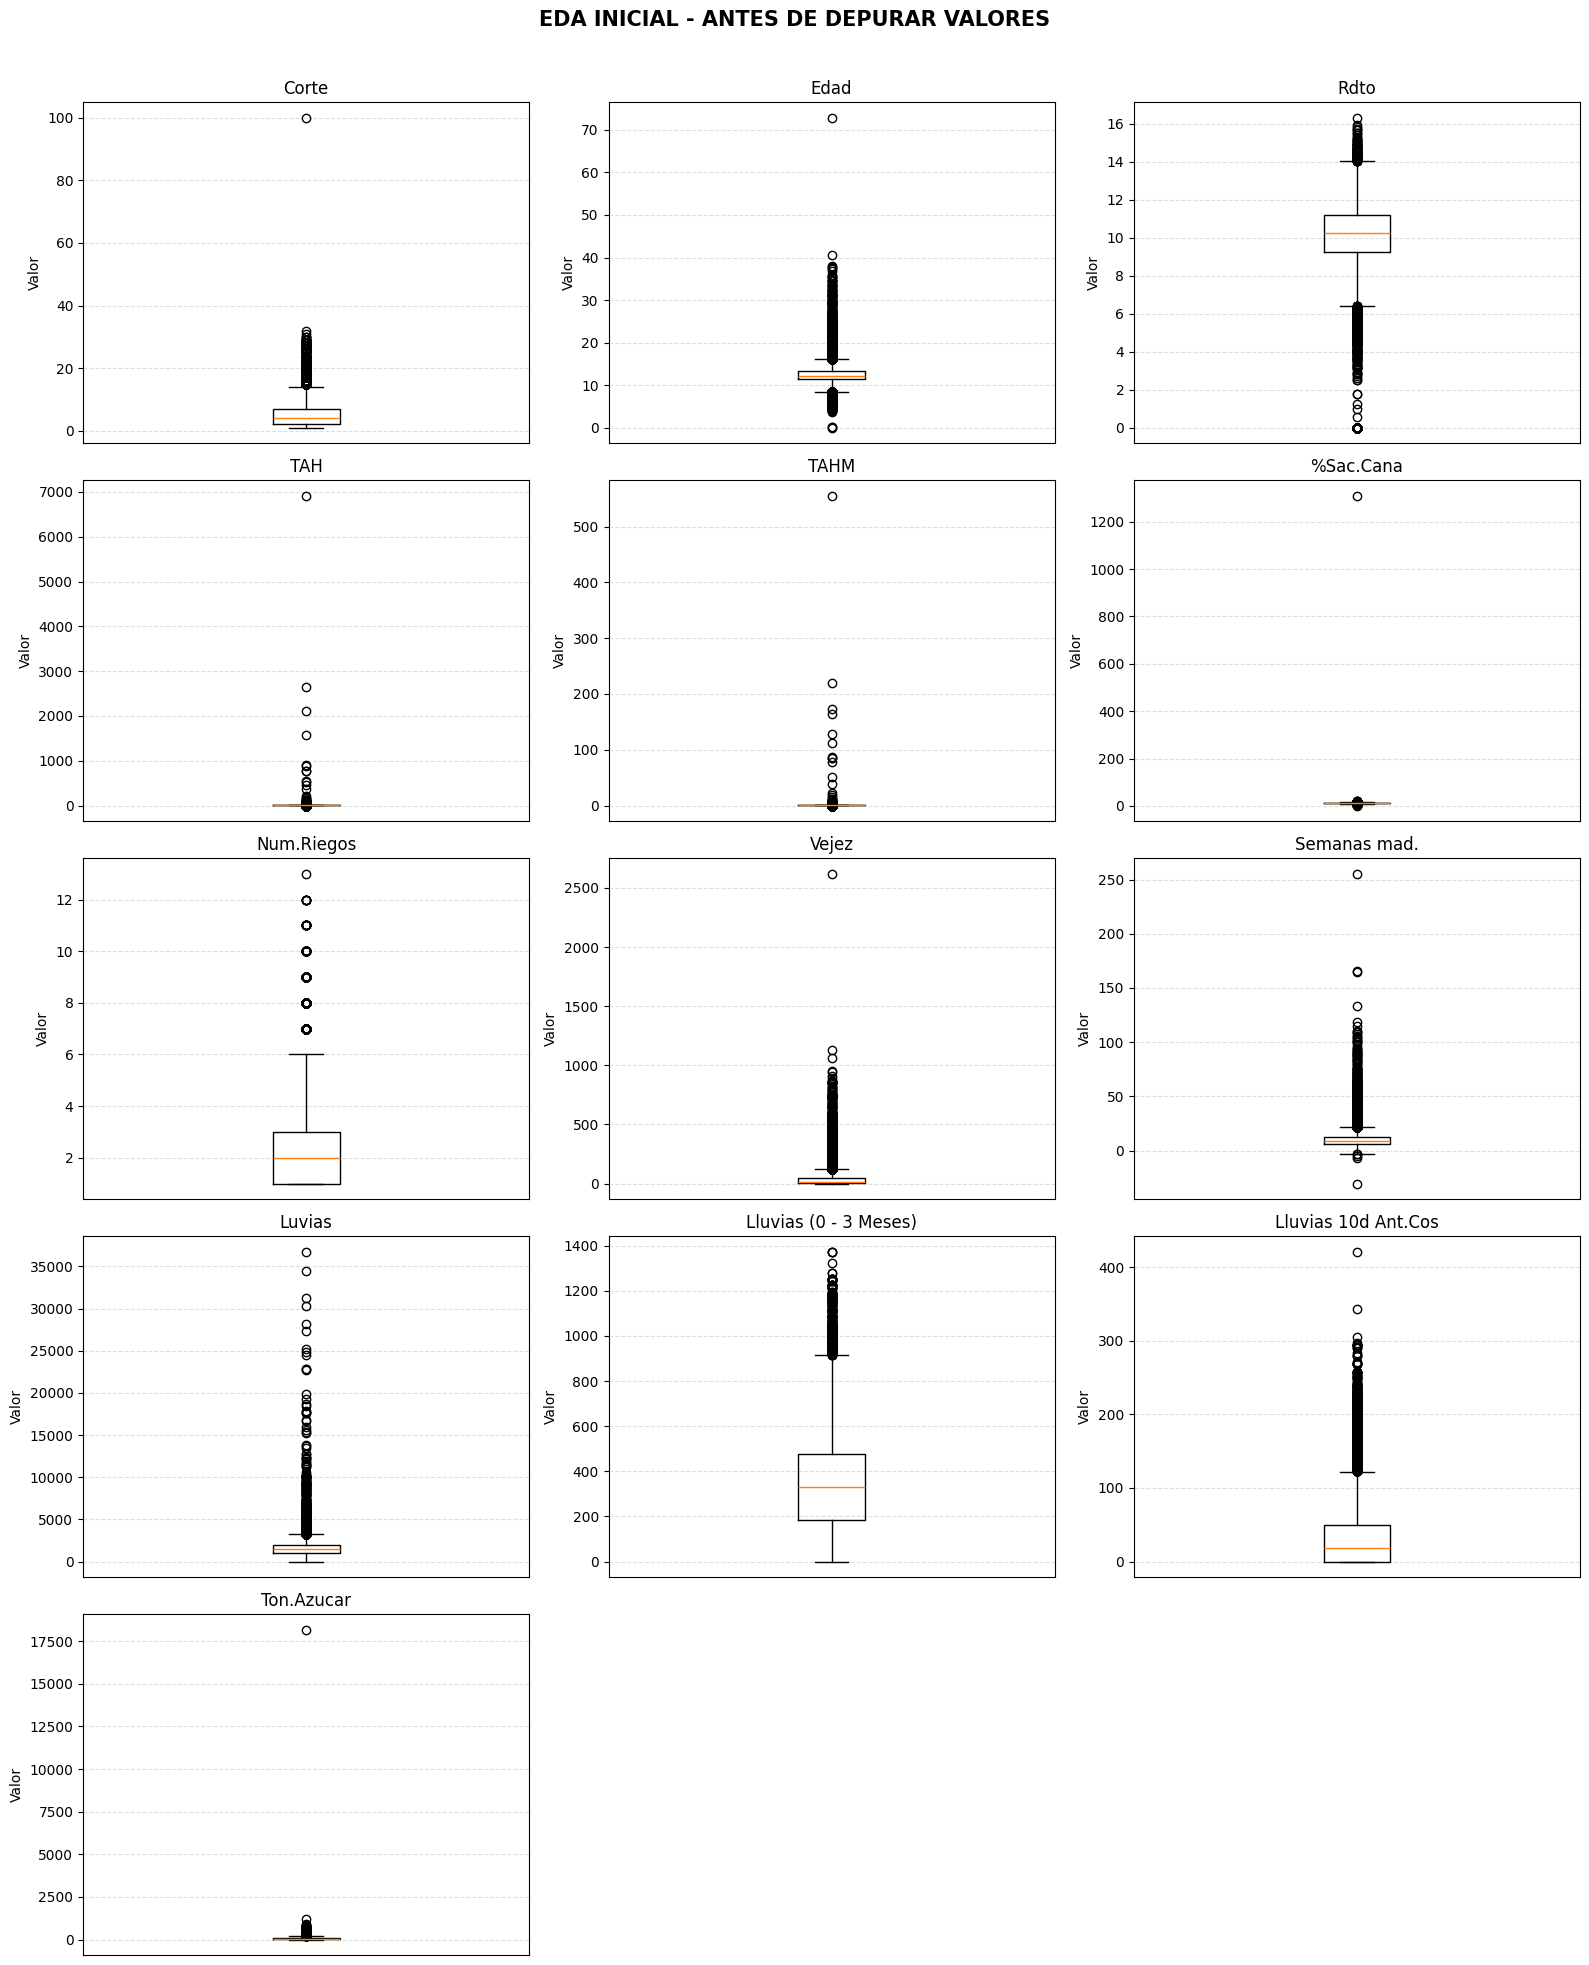


LÍMITES IQR INICIALES


,Variable,Q1,Q3,IQR,Límite inferior IQR,Límite superior IQR,Candidatos inferiores IQR,Candidatos superiores IQR,Candidatos totales IQR
0,Corte,2.0000,7.0000,5.0000,-5.5000,14.5000,0,3140,3140
1,Edad,11.4000,13.3400,1.9400,8.4900,16.2500,2268,3285,5553
2,Rdto,9.2527,11.1661,1.9134,6.3826,14.0362,1609,167,1776
3,TAH,8.5657,13.3674,4.8017,1.3632,20.5700,1017,606,1623
4,TAHM,0.6996,1.0673,0.3677,0.1481,1.6188,1033,553,1586
5,%Sac.Cana,10.9723,12.8355,1.8632,8.1776,15.6303,702,283,985
6,Num.Riegos,1.0000,3.0000,2.0000,-2.0000,6.0000,0,701,701
7,Vejez,2.0990,50.5775,48.4785,-70.6187,123.2952,0,3537,3537
8,Semanas mad.,6.1429,12.2857,6.1429,-3.0714,21.5000,5,1946,1951
9,Luvias,1069.0000,1931.0000,862.0000,-224.0000,3224.0000,0,1284,1284



VALORES QUE SE EXCLUIRÁN POR VARIABLE


,Variable,Minimo_permitido,Maximo_permitido,Minimo_observado,Maximo_observado,Valores_bajo_minimo,Valores_sobre_maximo,Total_fuera_rango_original,Minimo_fuera_rango,Maximo_fuera_rango
0,Corte,0,100,1.0000,100.0000,0,0,0,NaN,NaN
1,Edad,5,40,0.1000,72.8000,22,2,24,0.1000,72.8000
2,Rdto,3,17,0.0000,16.3071,942,0,942,0.0000,2.9386
3,TAH,0,100,0.0000,6914.6750,0,19,19,102.9167,6914.6750
4,TAHM,0,10,0.0000,555.3956,0,17,17,10.8415,555.3956
5,%Sac.Cana,0,100,1.6060,1309.0000,0,1,1,1309.0000,1309.0000
6,Num.Riegos,0,14,1.0000,13.0000,0,0,0,NaN,NaN
7,Vejez,0,2700,0.0000,2619.8300,0,0,0,NaN,NaN
8,Semanas mad.,0,80,-30.2857,255.2857,30,41,71,-30.2857,255.2857
9,Luvias,0,4500,0.0000,36733.8000,0,367,367,4501.0000,36733.8000


Corte                        | Inferiores:       0 | Superiores:       0 | Valores excluidos:       0
Edad                         | Inferiores:      22 | Superiores:       2 | Valores excluidos:      24
Rdto                         | Inferiores:     942 | Superiores:       0 | Valores excluidos:     942
TAH                          | Inferiores:       0 | Superiores:      19 | Valores excluidos:      19
TAHM                         | Inferiores:       0 | Superiores:      17 | Valores excluidos:      17
%Sac.Cana                    | Inferiores:       0 | Superiores:       1 | Valores excluidos:       1
Num.Riegos                   | Inferiores:       0 | Superiores:       0 | Valores excluidos:       0
Vejez                        | Inferiores:       0 | Superiores:       0 | Valores excluidos:       0
Semanas mad.                 | Inferiores:      30 | Superiores:      41 | Valores excluidos:      71
Luvias                       | Inferiores:       0 | Superiores:     367 | Valores

,Registros_originales,Registros_finales,Filas_eliminadas,Filas_con_algun_valor_atipico,Celdas_con_valores_excluidos,Porcentaje_filas_afectadas
0,60693,60693,0,1435,1511,2.36



DETALLE DE VALORES EXCLUIDOS POR VARIABLE


,Variable,Minimo_permitido,Maximo_permitido,Valores_inferiores_excluidos,Valores_superiores_excluidos,Total_valores_excluidos,Registros_originales,Registros_finales,Filas_eliminadas
0,Corte,0,100,0,0,0,60693,60693,0
1,Edad,5,40,22,2,24,60693,60693,0
2,Rdto,3,17,942,0,942,60693,60693,0
3,TAH,0,100,0,19,19,60693,60693,0
4,TAHM,0,10,0,17,17,60693,60693,0
5,%Sac.Cana,0,100,0,1,1,60693,60693,0
6,Num.Riegos,0,14,0,0,0,60693,60693,0
7,Vejez,0,2700,0,0,0,60693,60693,0
8,Semanas mad.,0,80,30,41,71,60693,60693,0
9,Luvias,0,4500,0,367,367,60693,60693,0



IMPORTANTE: el total de valores excluidos puede ser mayor que el total de filas afectadas, porque una misma fila puede contener valores atípicos en varias variables.

COMPARACIÓN DE REGISTROS POR AÑO


,year,Registros_antes,Registros_despues,Diferencia_registros
0,2014,5365,5365,0
1,2015,5783,5783,0
2,2016,5384,5384,0
3,2017,5260,5260,0
4,2018,5780,5780,0
5,2019,5324,5324,0
6,2020,5069,5069,0
7,2021,4503,4503,0
8,2022,4281,4281,0
9,2023,4402,4402,0


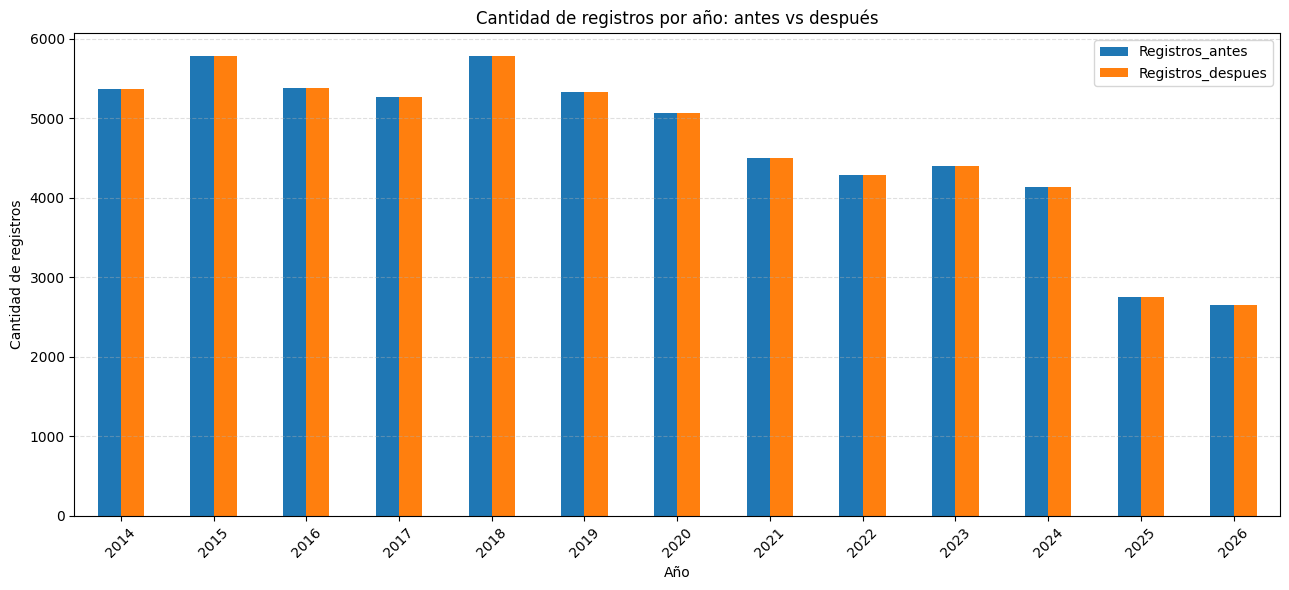

VERIFICACIÓN CORRECTA: se conservaron todos los registros de cada año.

EDA FINAL - DESPUÉS DE EXCLUIR VALORES ATÍPICOS


,Variable,Tipo,Registros,No vacíos,Vacíos,% vacíos,Únicos,No numéricos,Media,Mediana,Desv. est.,Mín,P25,P75,Máx
0,Variedad_TIFF,Cat,60693,60693,0,0.0000,58,,,,,,,,
1,Corte,Num,60693,60693,0,0.0000,33,0,5.306032,4.0,4.337781,1,2.0,7.0,100
2,Edad,Num,60693,60634,59,0.0972,691,0,12.479155,12.25,2.335958,5.09,11.4,13.34,37.95
3,Rdto,Num,60693,58915,1778,2.9295,35572,0,10.208669,10.2738,1.466555,3.0933,9.3086,11.18225,16.3071
4,TAH,Num,60693,60004,689,1.1352,57599,0,10.962203,11.019346,3.998157,0.0,8.564479,13.364789,95.461484
5,TAHM,Num,60693,59975,718,1.1830,57186,0,0.8818,0.891746,0.317962,0.0,0.69956,1.067064,10.0
6,%Sac.Cana,Num,60693,58897,1796,2.9592,30448,0,11.876324,11.9309,1.463816,1.606,10.9723,12.8355,20.25
7,Num.Riegos,Num,60693,20718,39975,65.8643,13,0,2.621682,2.0,1.694862,1.0,1.0,3.0,13.0
8,Vejez,Num,60693,59412,1281,2.1106,30928,0,36.318338,9.117,61.728572,0.0,2.099,50.5775,2619.83
9,Semanas mad.,Num,60693,26420,34273,56.4694,452,0,10.543403,8.714285,8.065906,0.0,6.142857,12.142857,80.0


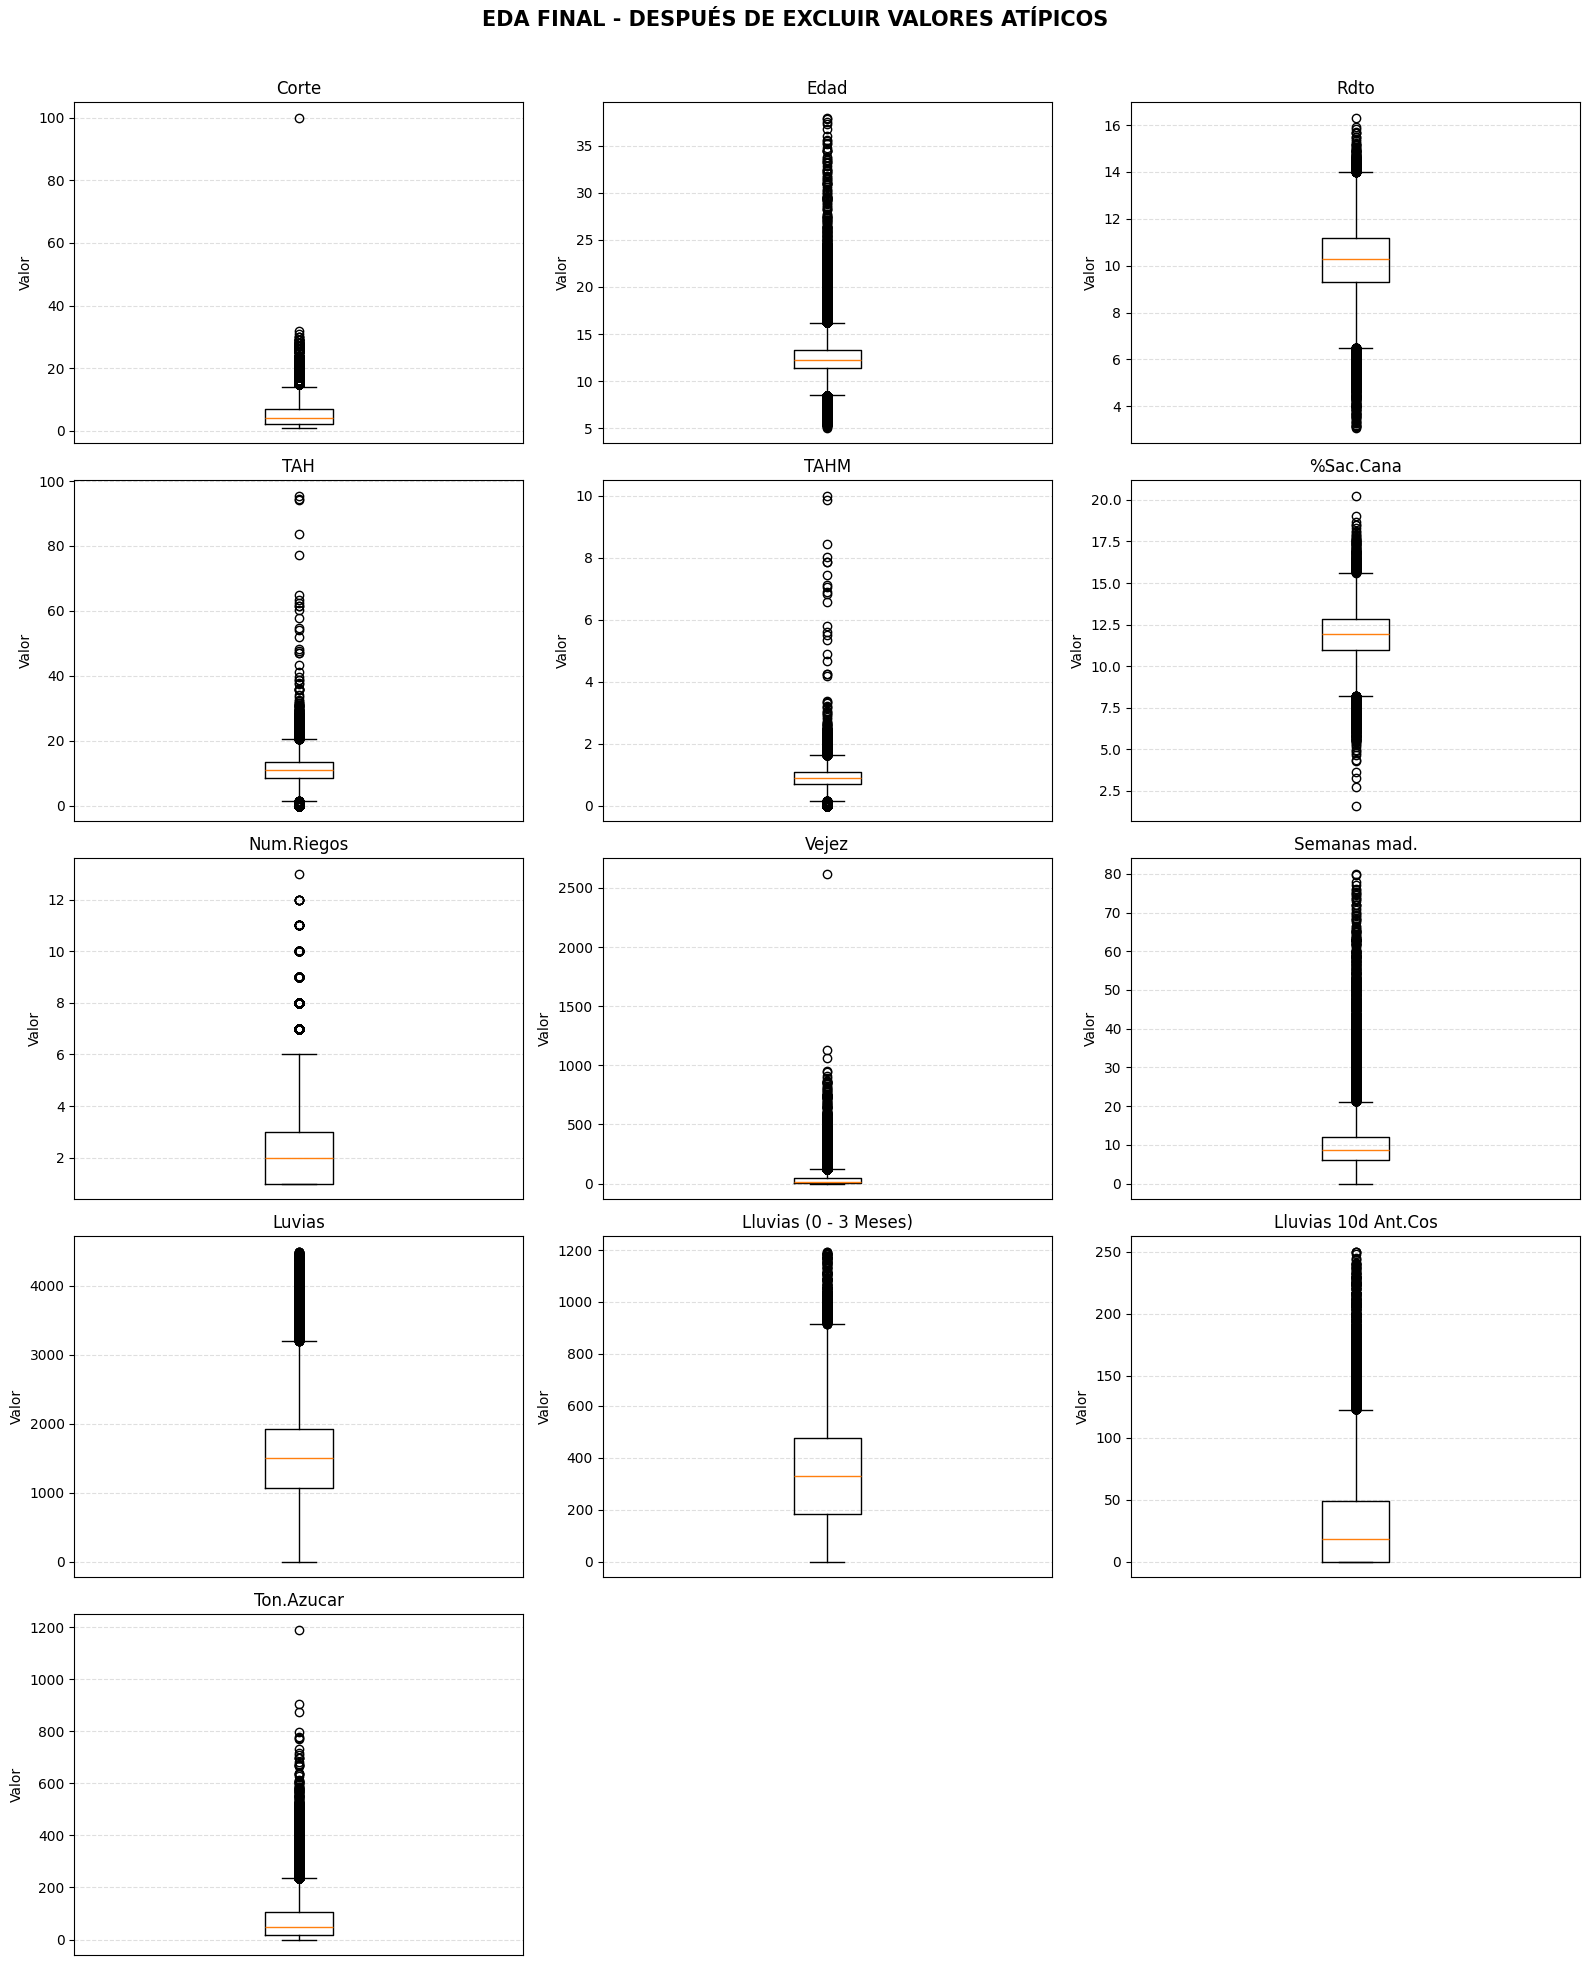


LÍMITES IQR DESPUÉS DE LA DEPURACIÓN


,Variable,Q1,Q3,IQR,Límite inferior IQR,Límite superior IQR,Candidatos inferiores IQR,Candidatos superiores IQR,Candidatos totales IQR
0,Corte,2.0000,7.0000,5.0000,-5.5000,14.5000,0,3140,3140
1,Edad,11.4000,13.3400,1.9400,8.4900,16.2500,2246,3283,5529
2,Rdto,9.3086,11.1822,1.8736,6.4981,13.9927,756,190,946
3,TAH,8.5645,13.3648,4.8003,1.3640,20.5653,1017,588,1605
4,TAHM,0.6996,1.0671,0.3675,0.1483,1.6183,1033,536,1569
5,%Sac.Cana,10.9723,12.8355,1.8632,8.1775,15.6303,702,282,984
6,Num.Riegos,1.0000,3.0000,2.0000,-2.0000,6.0000,0,701,701
7,Vejez,2.0990,50.5775,48.4785,-70.6187,123.2952,0,3537,3537
8,Semanas mad.,6.1429,12.1429,6.0000,-2.8571,21.1429,0,1957,1957
9,Luvias,1065.0000,1920.0000,855.0000,-217.5000,3202.5000,0,958,958



COMPARACIÓN EDA: ORIGINAL VS DEPURADO


,Variable,Tipo_Antes,Registros_Antes,No vacíos_Antes,Vacíos_Antes,% vacíos_Antes,Únicos_Antes,No numéricos_Antes,Media_Antes,Mediana_Antes,...,% vacíos_Despues,Únicos_Despues,No numéricos_Despues,Media_Despues,Mediana_Despues,Desv. est._Despues,Mín_Despues,P25_Despues,P75_Despues,Máx_Despues
0,%Sac.Cana,Num,60693,58898,1795,2.9575,30449,0,11.898347,11.9309,...,2.9592,30448,0,11.876324,11.9309,1.463816,1.606,10.9723,12.8355,20.25
1,Corte,Num,60693,60693,0,0.0000,33,0,5.306032,4.0,...,0.0000,33,0,5.306032,4.0,4.337781,1,2.0,7.0,100
2,Edad,Num,60693,60658,35,0.0577,712,0,12.477495,12.25,...,0.0972,691,0,12.479155,12.25,2.335958,5.09,11.4,13.34,37.95
3,Lluvias (0 - 3 Meses),Num,60693,60693,0,0.0000,1081,0,335.256191,329.0,...,0.0511,1068,0,334.787346,329.0,215.313067,0.0,182.0,475.0,1193.0
4,Lluvias 10d Ant.Cos,Num,60693,60693,0,0.0000,267,0,31.902921,18.0,...,0.0626,245,0,31.748331,18.0,37.844484,0.0,0.0,49.0,250.0
5,Luvias,Num,60693,46911,13782,22.7077,3723,0,1522.097862,1500.0,...,23.3124,3403,0,1475.353824,1495.0,768.88537,0.0,1065.0,1920.0,4492.0
6,Num.Riegos,Num,60693,20718,39975,65.8643,13,0,2.621682,2.0,...,65.8643,13,0,2.621682,2.0,1.694862,1.0,1.0,3.0,13.0
7,Rdto,Num,60693,59857,836,1.3774,35586,0,10.048478,10.2471,...,2.9295,35572,0,10.208669,10.2738,1.466555,3.0933,9.3086,11.18225,16.3071
8,Semanas mad.,Num,60693,26491,34202,56.3525,511,0,10.672498,8.714285,...,56.4694,452,0,10.543403,8.714285,8.065906,0.0,6.142857,12.142857,80.0
9,TAH,Num,60693,60023,670,1.1039,57618,0,11.283781,11.021015,...,1.1352,57599,0,10.962203,11.019346,3.998157,0.0,8.564479,13.364789,95.461484



COMPARACIÓN DE LÍMITES IQR


,Variable,Q1_Antes,Q3_Antes,IQR_Antes,Límite inferior IQR_Antes,Límite superior IQR_Antes,Candidatos inferiores IQR_Antes,Candidatos superiores IQR_Antes,Candidatos totales IQR_Antes,Q1_Despues,Q3_Despues,IQR_Despues,Límite inferior IQR_Despues,Límite superior IQR_Despues,Candidatos inferiores IQR_Despues,Candidatos superiores IQR_Despues,Candidatos totales IQR_Despues
0,%Sac.Cana,10.9723,12.8355,1.8632,8.1776,15.6303,702,283,985,10.9723,12.8355,1.8632,8.1775,15.6303,702,282,984
1,Corte,2.0000,7.0000,5.0000,-5.5000,14.5000,0,3140,3140,2.0000,7.0000,5.0000,-5.5000,14.5000,0,3140,3140
2,Edad,11.4000,13.3400,1.9400,8.4900,16.2500,2268,3285,5553,11.4000,13.3400,1.9400,8.4900,16.2500,2246,3283,5529
3,Lluvias (0 - 3 Meses),182.0000,475.0000,293.0000,-257.5000,914.5000,0,466,466,182.0000,475.0000,293.0000,-257.5000,914.5000,0,435,435
4,Lluvias 10d Ant.Cos,0.0000,49.0000,49.0000,-73.5000,122.5000,0,2081,2081,0.0000,49.0000,49.0000,-73.5000,122.5000,0,2043,2043
5,Luvias,1069.0000,1931.0000,862.0000,-224.0000,3224.0000,0,1284,1284,1065.0000,1920.0000,855.0000,-217.5000,3202.5000,0,958,958
6,Num.Riegos,1.0000,3.0000,2.0000,-2.0000,6.0000,0,701,701,1.0000,3.0000,2.0000,-2.0000,6.0000,0,701,701
7,Rdto,9.2527,11.1661,1.9134,6.3826,14.0362,1609,167,1776,9.3086,11.1822,1.8736,6.4981,13.9927,756,190,946
8,Semanas mad.,6.1429,12.2857,6.1429,-3.0714,21.5000,5,1946,1951,6.1429,12.1429,6.0000,-2.8571,21.1429,0,1957,1957
9,TAH,8.5657,13.3674,4.8017,1.3632,20.5700,1017,606,1623,8.5645,13.3648,4.8003,1.3640,20.5653,1017,588,1605


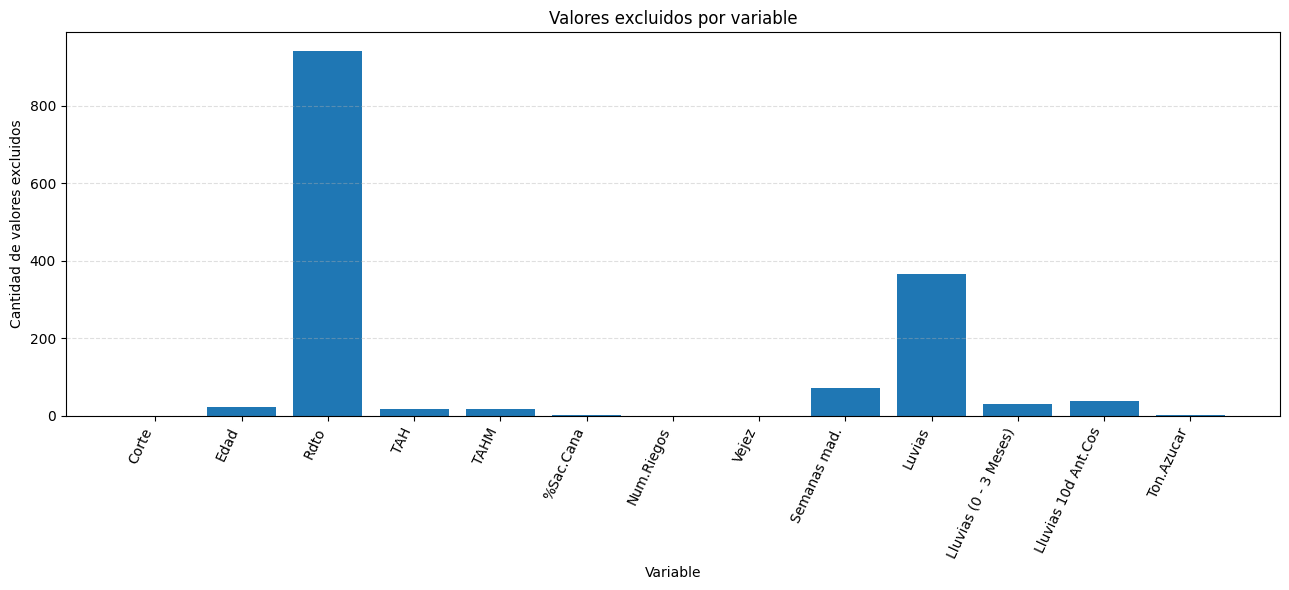

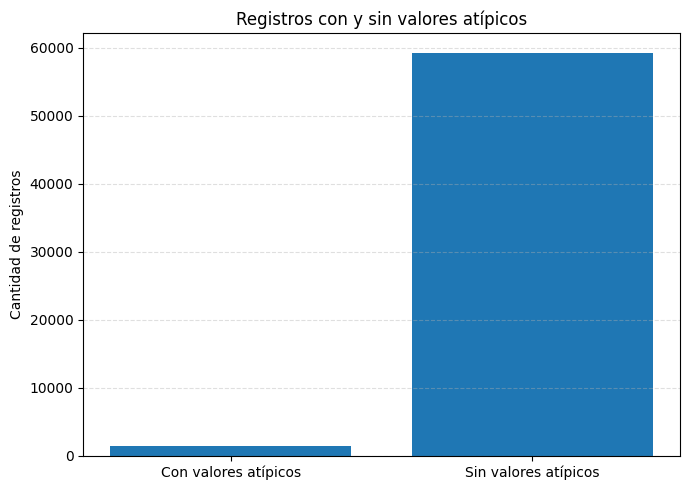


VERIFICACIONES FINALES
Registros originales: 60,693
Registros finales:    60,693
Filas eliminadas:     0
Filas con algún valor atípico: 1,435
Valores individuales excluidos: 1,511

CORRECTO: se conservaron todas las filas y sus índices originales.
Los valores fuera de rango se sustituyeron únicamente en sus respectivas columnas.

PROCESO FINALIZADO
Archivo de auditoría generado:
C:\Users\jjruiz\Downloads\Auditoria_Valores_Atipicos.xlsx

DataFrames disponibles:
df_original_rangos          -> Excel original sin modificaciones
df_limpio_rangos            -> Datos con valores atípicos como NaN
df_resumen_general_rangos   -> Resumen general
df_resumen_rangos_original  -> Conteos fuera de rango por variable
df_historial_rangos         -> Resumen de depuración por variable
df_auditoria_atipicos       -> Detalle de cada valor excluido
df_resumen_anios_rangos     -> Comparación de filas por año
eda_comparativo_rangos      -> Comparación del EDA
iqr_comparativo_rangos      -> Comparación de lím

In [ ]:
#  3 
# ============================================================
# DEPURACIÓN DE VALORES ATÍPICOS SIN ELIMINAR REGISTROS
# EDA INICIAL + LIMPIEZA POR VARIABLE + EDA FINAL
# ============================================================
#
# OBJETIVO:
#   - Conservar todos los registros originales.
#   - Reemplazar únicamente los valores fuera de rango por NaN.
#   - Conservar el resto de los atributos de cada registro.
#   - Mostrar los EDA y gráficos antes y después.
#   - Comparar estadísticas, rangos y registros por año.
#   - Generar una auditoría de los valores excluidos.
#
# EJEMPLO:
#   Corte = 200 -> Corte pasa a NaN.
#   Edad, TAH, CODSIA y los demás campos se conservan.
#
# ============================================================

import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

ARCHIVO_EXCEL = r"C:\Users\jjruiz\OneDrive - Sector Agro\Geodata\Analisis datos a raster\TEMP\depurados\Reporte_Biosal.xlsx"
HOJA_EXCEL = "Data_original"

FACTOR_IQR = 1.5

# Variables que se analizarán en el EDA.
VARIABLES_EDA = [
    "Variedad_TIFF",
    "Corte",
    "Edad",
    "Rdto",
    "TAH",
    "TAHM",
    "%Sac.Cana",
    "Num.Riegos",
    "Vejez",
    "Semanas mad.",
    "Luvias",
    "Lluvias (0 - 3 Meses)",
    "Lluvias 10d Ant.Cos",
    "Ton.Azucar",
]

# Variable categórica: no se le aplican límites numéricos.
VARIABLES_CATEGORICAS = [
    "Variedad_TIFF",
]

# Rangos permitidos definidos por ti.
# Los valores iguales a los límites se conservan.
RANGOS_DEPURACION = {
    "Corte": (0, 100),
    "Edad": (5, 40),
    "Rdto": (3, 17),
    "TAH": (0, 100),
    "TAHM": (0, 10),
    "%Sac.Cana": (0, 100),
    "Num.Riegos": (0, 14),
    "Vejez": (0, 2700),
    "Semanas mad.": (0, 80),
    "Luvias": (0, 4500),
    "Lluvias (0 - 3 Meses)": (0, 1200),
    "Lluvias 10d Ant.Cos": (0, 250),
    "Ton.Azucar": (0, 2300),
}

# Columnas que deben conservarse como texto.
COLUMNAS_TEXTO = [
    "Llave",
    "Periodos",
    "Archivo_origen",
    "Periodo",
    "CODSIA",
    "Hacienda",
    "Suerte",
    "Poligono",
    "Capa_producto_final",
    "Nombre",
    "Zona",
    "G.Tenencia",
    "Tenencia",
]

# Carpeta y archivo de resultados de auditoría.
CARPETA_SALIDA = os.path.dirname(
    os.path.abspath(ARCHIVO_EXCEL)
)

ARCHIVO_AUDITORIA = os.path.join(
    CARPETA_SALIDA,
    "Auditoria_Valores_Atipicos.xlsx"
)


# ============================================================
# 2. FUNCIONES AUXILIARES
# ============================================================

def convertir_analisis_numerico(serie):
    """
    Convierte temporalmente una serie a numérica para análisis.
    No modifica la serie original.
    Admite coma decimal.
    """

    if pd.api.types.is_numeric_dtype(serie):
        return pd.to_numeric(
            serie,
            errors="coerce"
        )

    serie_texto = (
        serie.astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )

    return pd.to_numeric(
        serie_texto,
        errors="coerce"
    )


def calcular_eda(df):
    """
    Calcula estadísticas descriptivas de las variables EDA.
    Los vacíos se calculan sobre los valores originales.
    """

    resultados = []
    total = len(df)

    for col in VARIABLES_EDA:

        serie_original = df[col]

        no_vacios = int(serie_original.notna().sum())
        vacios = int(serie_original.isna().sum())

        if col in VARIABLES_CATEGORICAS:

            valores = serie_original.dropna()

            resultados.append({
                "Variable": col,
                "Tipo": "Cat",
                "Registros": total,
                "No vacíos": no_vacios,
                "Vacíos": vacios,
                "% vacíos": (
                    vacios / total * 100 if total else 0
                ),
                "Únicos": valores.nunique(),
                "No numéricos": "",
                "Media": "",
                "Mediana": "",
                "Desv. est.": "",
                "Mín": "",
                "P25": "",
                "P75": "",
                "Máx": "",
            })

            continue

        numerica = convertir_analisis_numerico(
            serie_original
        )

        no_numericos = int(
            (
                serie_original.notna()
                & numerica.isna()
            ).sum()
        )

        valores = numerica.dropna()

        if valores.empty:
            media = None
            mediana = None
            desviacion = None
            minimo = None
            p25 = None
            p75 = None
            maximo = None
            unicos = 0

        else:
            media = valores.mean()
            mediana = valores.median()
            desviacion = valores.std()
            minimo = valores.min()
            p25 = valores.quantile(0.25)
            p75 = valores.quantile(0.75)
            maximo = valores.max()
            unicos = valores.nunique()

        resultados.append({
            "Variable": col,
            "Tipo": "Num",
            "Registros": total,
            "No vacíos": no_vacios,
            "Vacíos": vacios,
            "% vacíos": (
                vacios / total * 100 if total else 0
            ),
            "Únicos": unicos,
            "No numéricos": no_numericos,
            "Media": media,
            "Mediana": mediana,
            "Desv. est.": desviacion,
            "Mín": minimo,
            "P25": p25,
            "P75": p75,
            "Máx": maximo,
        })

    return pd.DataFrame(resultados)


def calcular_limites_iqr(df):
    """
    Calcula los límites estadísticos IQR.
    No elimina ni modifica datos.
    """

    resultados = []

    for col in VARIABLES_EDA:

        if col in VARIABLES_CATEGORICAS:
            continue

        valores = convertir_analisis_numerico(
            df[col]
        ).dropna()

        if valores.empty:

            resultados.append({
                "Variable": col,
                "Q1": None,
                "Q3": None,
                "IQR": None,
                "Límite inferior IQR": None,
                "Límite superior IQR": None,
                "Candidatos inferiores IQR": 0,
                "Candidatos superiores IQR": 0,
                "Candidatos totales IQR": 0,
            })

            continue

        q1 = valores.quantile(0.25)
        q3 = valores.quantile(0.75)
        iqr = q3 - q1

        limite_inf = q1 - FACTOR_IQR * iqr
        limite_sup = q3 + FACTOR_IQR * iqr

        n_inf = int((valores < limite_inf).sum())
        n_sup = int((valores > limite_sup).sum())

        resultados.append({
            "Variable": col,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Límite inferior IQR": limite_inf,
            "Límite superior IQR": limite_sup,
            "Candidatos inferiores IQR": n_inf,
            "Candidatos superiores IQR": n_sup,
            "Candidatos totales IQR": n_inf + n_sup,
        })

    return pd.DataFrame(resultados)


def mostrar_eda(df, titulo):
    """
    Muestra la tabla EDA y los diagramas de caja y bigotes.
    """

    eda = calcular_eda(df)

    print("\n" + "=" * 110)
    print(titulo)
    print("=" * 110)

    display(eda.round(4))

    variables_numericas = [
        c for c in VARIABLES_EDA
        if c not in VARIABLES_CATEGORICAS
    ]

    columnas = 3
    filas = math.ceil(
        len(variables_numericas) / columnas
    )

    fig, axes = plt.subplots(
        filas,
        columnas,
        figsize=(16, 4 * filas)
    )

    axes = np.asarray(axes).flatten()

    for i, col in enumerate(variables_numericas):

        valores = convertir_analisis_numerico(
            df[col]
        ).dropna()

        if valores.empty:
            axes[i].set_title(f"{col} - Sin datos")
            axes[i].set_visible(True)
            continue

        axes[i].boxplot(
            valores,
            whis=FACTOR_IQR,
            showfliers=True
        )

        axes[i].set_title(col)
        axes[i].set_ylabel("Valor")
        axes[i].set_xticks([])
        axes[i].grid(
            axis="y",
            linestyle="--",
            alpha=0.4
        )

    for i in range(len(variables_numericas), len(axes)):
        axes[i].set_visible(False)

    fig.suptitle(
        titulo,
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

    return eda


# ============================================================
# 3. CARGAR EXCEL ORIGINAL
# ============================================================

if not os.path.exists(ARCHIVO_EXCEL):
    raise FileNotFoundError(
        f"No se encontró el archivo:\n{ARCHIVO_EXCEL}"
    )

print("=" * 100)
print("CARGA DEL EXCEL ORIGINAL")
print("=" * 100)

df_original_rangos = pd.read_excel(
    ARCHIVO_EXCEL,
    sheet_name=HOJA_EXCEL,
    dtype={
        col: "string"
        for col in COLUMNAS_TEXTO
    }
).reset_index(drop=True)

# Identificador permanente para relacionar la auditoría
# con la fila original del Excel.
df_original_rangos.index.name = "Indice_original"

# Guardamos el original y no lo modificamos.
df_original_rangos = df_original_rangos.copy(deep=True)

columnas_faltantes = [
    col for col in VARIABLES_EDA
    if col not in df_original_rangos.columns
]

if columnas_faltantes:
    raise ValueError(
        "Faltan variables EDA en el Excel:\n"
        + "\n".join(columnas_faltantes)
    )

columnas_rango_faltantes = [
    col for col in RANGOS_DEPURACION
    if col not in df_original_rangos.columns
]

if columnas_rango_faltantes:
    raise ValueError(
        "Faltan variables con rangos definidos:\n"
        + "\n".join(columnas_rango_faltantes)
    )

TOTAL_ORIGINAL = len(df_original_rangos)

if TOTAL_ORIGINAL == 0:
    raise ValueError("El Excel no contiene registros.")

print(f"Archivo: {ARCHIVO_EXCEL}")
print(f"Hoja: {HOJA_EXCEL}")
print(f"Registros originales: {TOTAL_ORIGINAL:,}")
print(f"Columnas originales: {len(df_original_rangos.columns)}")

if "year" in df_original_rangos.columns:
    print(
        "Años encontrados:",
        sorted(
            df_original_rangos["year"]
            .dropna()
            .astype(str)
            .unique()
            .tolist()
        )
    )


# ============================================================
# 4. EDA INICIAL Y GRÁFICOS
# ============================================================

eda_antes_rangos = mostrar_eda(
    df_original_rangos,
    "EDA INICIAL - ANTES DE DEPURAR VALORES"
)

iqr_antes_rangos = calcular_limites_iqr(
    df_original_rangos
)

print("\nLÍMITES IQR INICIALES")
display(iqr_antes_rangos.round(4))


# ============================================================
# 5. IDENTIFICAR VALORES FUERA DE LOS RANGOS DEFINIDOS
# ============================================================

resumen_inicial = []
mascaras_originales = {}

for variable, (minimo, maximo) in RANGOS_DEPURACION.items():

    valores = convertir_analisis_numerico(
        df_original_rangos[variable]
    )

    mascara_inferior = (
        valores.notna()
        & (valores < minimo)
    )

    mascara_superior = (
        valores.notna()
        & (valores > maximo)
    )

    mascara_fuera = (
        mascara_inferior
        | mascara_superior
    )

    mascaras_originales[variable] = mascara_fuera

    valores_fuera = valores[mascara_fuera]

    resumen_inicial.append({
        "Variable": variable,
        "Minimo_permitido": minimo,
        "Maximo_permitido": maximo,
        "Minimo_observado": valores.min(),
        "Maximo_observado": valores.max(),
        "Valores_bajo_minimo": int(mascara_inferior.sum()),
        "Valores_sobre_maximo": int(mascara_superior.sum()),
        "Total_fuera_rango_original": int(mascara_fuera.sum()),
        "Minimo_fuera_rango": (
            valores_fuera.min()
            if not valores_fuera.empty else np.nan
        ),
        "Maximo_fuera_rango": (
            valores_fuera.max()
            if not valores_fuera.empty else np.nan
        ),
    })

df_resumen_rangos_original = pd.DataFrame(
    resumen_inicial
)

print("\n" + "=" * 110)
print("VALORES QUE SE EXCLUIRÁN POR VARIABLE")
print("=" * 110)

display(df_resumen_rangos_original.round(4))


# ============================================================
# 6. COPIAR EL DATAFRAME Y REEMPLAZAR SOLO VALORES ATÍPICOS
# ============================================================
#
# IMPORTANTE:
#   NO se elimina ninguna fila.
#   Solo se reemplaza el valor fuera de rango por NaN.
#   Las demás columnas de esa fila permanecen intactas.
#
# ============================================================

df_limpio_rangos = df_original_rangos.copy(deep=True)

auditoria_valores = []
historial_rangos = []

for variable, (minimo, maximo) in RANGOS_DEPURACION.items():

    valores_numericos = convertir_analisis_numerico(
        df_original_rangos[variable]
    )

    mascara_inferior = (
        valores_numericos.notna()
        & (valores_numericos < minimo)
    )

    mascara_superior = (
        valores_numericos.notna()
        & (valores_numericos > maximo)
    )

    mascara_fuera = (
        mascara_inferior
        | mascara_superior
    )

    indices_fuera = df_original_rangos.index[
        mascara_fuera
    ]

    cantidad_inferior = int(mascara_inferior.sum())
    cantidad_superior = int(mascara_superior.sum())
    cantidad_fuera = int(mascara_fuera.sum())

    # --------------------------------------------------------
    # AUDITORÍA: registrar cada valor que será invalidado.
    # --------------------------------------------------------

    for indice in indices_fuera:

        registro = {
            "Indice_original": indice,
            "Variable": variable,
            "Valor_original": df_original_rangos.at[
                indice, variable
            ],
            "Valor_numerico_analizado": valores_numericos.loc[
                indice
            ],
            "Minimo_permitido": minimo,
            "Maximo_permitido": maximo,
            "Motivo": (
                "Inferior al mínimo"
                if valores_numericos.loc[indice] < minimo
                else "Superior al máximo"
            ),
        }

        # Agregar identificadores disponibles para facilitar
        # la localización del registro en el Excel.
        for columna in [
            "Llave",
            "year",
            "Periodos",
            "Periodo",
            "CODSIA",
            "Hacienda",
            "Suerte",
            "Capa_producto_final",
        ]:
            if columna in df_original_rangos.columns:
                registro[columna] = (
                    df_original_rangos.at[indice, columna]
                )

        auditoria_valores.append(registro)

    # --------------------------------------------------------
    # DEPURACIÓN: solo la celda fuera de rango se vuelve NaN.
    # --------------------------------------------------------

    if cantidad_fuera > 0:

        df_limpio_rangos.loc[
            mascara_fuera,
            variable
        ] = np.nan

    # --------------------------------------------------------
    # HISTORIAL POR VARIABLE
    # --------------------------------------------------------

    historial_rangos.append({
        "Variable": variable,
        "Minimo_permitido": minimo,
        "Maximo_permitido": maximo,
        "Valores_inferiores_excluidos": cantidad_inferior,
        "Valores_superiores_excluidos": cantidad_superior,
        "Total_valores_excluidos": cantidad_fuera,
        "Registros_originales": TOTAL_ORIGINAL,
        "Registros_finales": len(df_limpio_rangos),
        "Filas_eliminadas": 0,
    })

    print(
        f"{variable:28s} | "
        f"Inferiores: {cantidad_inferior:>7,} | "
        f"Superiores: {cantidad_superior:>7,} | "
        f"Valores excluidos: {cantidad_fuera:>7,}"
    )

df_historial_rangos = pd.DataFrame(
    historial_rangos
)

if auditoria_valores:
    df_auditoria_atipicos = pd.DataFrame(
        auditoria_valores
    )
else:
    df_auditoria_atipicos = pd.DataFrame(
        columns=[
            "Indice_original",
            "Variable",
            "Valor_original",
            "Valor_numerico_analizado",
            "Minimo_permitido",
            "Maximo_permitido",
            "Motivo",
        ]
    )


# ============================================================
# 7. RESUMEN GENERAL DE LA DEPURACIÓN
# ============================================================

TOTAL_FINAL = len(df_limpio_rangos)

# Conteo de celdas fuera de rango, no de filas.
TOTAL_VALORES_EXCLUIDOS = int(
    df_historial_rangos["Total_valores_excluidos"].sum()
)

# Una misma fila puede tener varios valores excluidos.
# Por eso el número de valores excluidos no representa
# el número de registros eliminados.

mascara_fila_afectada = pd.Series(
    False,
    index=df_original_rangos.index
)

for mascara in mascaras_originales.values():
    mascara_fila_afectada |= mascara

TOTAL_FILAS_AFECTADAS = int(
    mascara_fila_afectada.sum()
)

df_resumen_general_rangos = pd.DataFrame([{
    "Registros_originales": TOTAL_ORIGINAL,
    "Registros_finales": TOTAL_FINAL,
    "Filas_eliminadas": TOTAL_ORIGINAL - TOTAL_FINAL,
    "Filas_con_algun_valor_atipico": TOTAL_FILAS_AFECTADAS,
    "Celdas_con_valores_excluidos": TOTAL_VALORES_EXCLUIDOS,
    "Porcentaje_filas_afectadas": (
        TOTAL_FILAS_AFECTADAS / TOTAL_ORIGINAL * 100
        if TOTAL_ORIGINAL else 0
    ),
}])

print("\n" + "=" * 110)
print("RESUMEN GENERAL DE DEPURACIÓN")
print("=" * 110)

display(df_resumen_general_rangos.round(2))

print("\nDETALLE DE VALORES EXCLUIDOS POR VARIABLE")
display(df_historial_rangos)

print(
    "\nIMPORTANTE: el total de valores excluidos puede ser "
    "mayor que el total de filas afectadas, porque una misma "
    "fila puede contener valores atípicos en varias variables."
)


# ============================================================
# 8. COMPARACIÓN DE REGISTROS POR AÑO
# ============================================================
#
# Como no se eliminan filas, los conteos por año deben
# mantenerse exactamente iguales.
#
# ============================================================

if "year" in df_original_rangos.columns:

    antes_anio = (
        df_original_rangos.groupby(
            "year",
            dropna=False
        )
        .size()
        .rename("Registros_antes")
    )

    despues_anio = (
        df_limpio_rangos.groupby(
            "year",
            dropna=False
        )
        .size()
        .rename("Registros_despues")
    )

    df_resumen_anios_rangos = pd.concat(
        [
            antes_anio,
            despues_anio
        ],
        axis=1
    ).fillna(0)

    df_resumen_anios_rangos = (
        df_resumen_anios_rangos
        .astype(int)
        .reset_index()
    )

    df_resumen_anios_rangos[
        "Diferencia_registros"
    ] = (
        df_resumen_anios_rangos["Registros_antes"]
        - df_resumen_anios_rangos["Registros_despues"]
    )

    print("\n" + "=" * 110)
    print("COMPARACIÓN DE REGISTROS POR AÑO")
    print("=" * 110)

    display(df_resumen_anios_rangos)

    ax = df_resumen_anios_rangos.plot(
        x="year",
        y=[
            "Registros_antes",
            "Registros_despues",
        ],
        kind="bar",
        figsize=(13, 6)
    )

    ax.set_title(
        "Cantidad de registros por año: antes vs después"
    )

    ax.set_xlabel("Año")
    ax.set_ylabel("Cantidad de registros")
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.4
    )

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Comprobación automática.
    if (
        df_resumen_anios_rangos[
            "Diferencia_registros"
        ] == 0
    ).all():
        print(
            "VERIFICACIÓN CORRECTA: se conservaron "
            "todos los registros de cada año."
        )
    else:
        print(
            "ADVERTENCIA: se detectó una diferencia "
            "en los conteos por año."
        )

else:
    df_resumen_anios_rangos = pd.DataFrame()

    print(
        "No existe la columna 'year'; "
        "no se puede generar la comparación por año."
    )


# ============================================================
# 9. EDA FINAL Y GRÁFICOS
# ============================================================

eda_despues_rangos = mostrar_eda(
    df_limpio_rangos,
    "EDA FINAL - DESPUÉS DE EXCLUIR VALORES ATÍPICOS"
)

iqr_despues_rangos = calcular_limites_iqr(
    df_limpio_rangos
)

print("\nLÍMITES IQR DESPUÉS DE LA DEPURACIÓN")
display(iqr_despues_rangos.round(4))


# ============================================================
# 10. COMPARACIÓN EDA INICIAL VS FINAL
# ============================================================

eda_comparativo_rangos = eda_antes_rangos.merge(
    eda_despues_rangos,
    on="Variable",
    how="outer",
    suffixes=("_Antes", "_Despues")
)

print("\n" + "=" * 110)
print("COMPARACIÓN EDA: ORIGINAL VS DEPURADO")
print("=" * 110)

display(eda_comparativo_rangos.round(4))


# ============================================================
# 11. COMPARACIÓN IQR INICIAL VS FINAL
# ============================================================

iqr_comparativo_rangos = iqr_antes_rangos.merge(
    iqr_despues_rangos,
    on="Variable",
    how="outer",
    suffixes=("_Antes", "_Despues")
)

print("\n" + "=" * 110)
print("COMPARACIÓN DE LÍMITES IQR")
print("=" * 110)

display(iqr_comparativo_rangos.round(4))


# ============================================================
# 12. GRÁFICO DE VALORES EXCLUIDOS POR VARIABLE
# ============================================================

plt.figure(figsize=(13, 6))

plt.bar(
    df_historial_rangos["Variable"],
    df_historial_rangos["Total_valores_excluidos"]
)

plt.title("Valores excluidos por variable")
plt.xlabel("Variable")
plt.ylabel("Cantidad de valores excluidos")

plt.xticks(
    rotation=65,
    ha="right"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()


# ============================================================
# 13. GRÁFICO DE FILAS AFECTADAS VS NO AFECTADAS
# ============================================================

filas_no_afectadas = (
    TOTAL_ORIGINAL - TOTAL_FILAS_AFECTADAS
)

plt.figure(figsize=(7, 5))

plt.bar(
    ["Con valores atípicos", "Sin valores atípicos"],
    [
        TOTAL_FILAS_AFECTADAS,
        filas_no_afectadas,
    ]
)

plt.title("Registros con y sin valores atípicos")
plt.ylabel("Cantidad de registros")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()


# ============================================================
# 14. VERIFICACIONES FINALES
# ============================================================

print("\n" + "=" * 110)
print("VERIFICACIONES FINALES")
print("=" * 110)

print(f"Registros originales: {TOTAL_ORIGINAL:,}")
print(f"Registros finales:    {TOTAL_FINAL:,}")
print(
    f"Filas eliminadas:     "
    f"{TOTAL_ORIGINAL - TOTAL_FINAL:,}"
)
print(
    f"Filas con algún valor atípico: "
    f"{TOTAL_FILAS_AFECTADAS:,}"
)
print(
    f"Valores individuales excluidos: "
    f"{TOTAL_VALORES_EXCLUIDOS:,}"
)

assert TOTAL_ORIGINAL == TOTAL_FINAL, (
    "ERROR: el número de filas cambió."
)

assert df_original_rangos.index.equals(
    df_limpio_rangos.index
), "ERROR: los índices de las filas no coinciden."

print(
    "\nCORRECTO: se conservaron todas las filas "
    "y sus índices originales."
)

print(
    "Los valores fuera de rango se sustituyeron "
    "únicamente en sus respectivas columnas."
)


# ============================================================
# 15. EXPORTAR AUDITORÍA Y RESULTADOS
# ============================================================

with pd.ExcelWriter(
    ARCHIVO_AUDITORIA,
    engine="openpyxl"
) as writer:

    df_limpio_rangos.to_excel(
        writer,
        sheet_name="Datos_Depurados",
        index=False
    )

    df_resumen_general_rangos.to_excel(
        writer,
        sheet_name="Resumen_General",
        index=False
    )

    df_resumen_rangos_original.to_excel(
        writer,
        sheet_name="Valores_Fuera_Rango",
        index=False
    )

    df_historial_rangos.to_excel(
        writer,
        sheet_name="Resumen_por_Variable",
        index=False
    )

    df_auditoria_atipicos.to_excel(
        writer,
        sheet_name="Auditoria_Detallada",
        index=False
    )

    df_resumen_anios_rangos.to_excel(
        writer,
        sheet_name="Resumen_por_Anio",
        index=False
    )

    eda_antes_rangos.to_excel(
        writer,
        sheet_name="EDA_Inicial",
        index=False
    )

    eda_despues_rangos.to_excel(
        writer,
        sheet_name="EDA_Final",
        index=False
    )

    eda_comparativo_rangos.to_excel(
        writer,
        sheet_name="Comparacion_EDA",
        index=False
    )

    iqr_comparativo_rangos.to_excel(
        writer,
        sheet_name="Comparacion_IQR",
        index=False
    )

print("\n" + "=" * 110)
print("PROCESO FINALIZADO")
print("=" * 110)

print(f"Archivo de auditoría generado:\n{ARCHIVO_AUDITORIA}")

print("\nDataFrames disponibles:")
print("df_original_rangos          -> Excel original sin modificaciones")
print("df_limpio_rangos            -> Datos con valores atípicos como NaN")
print("df_resumen_general_rangos   -> Resumen general")
print("df_resumen_rangos_original  -> Conteos fuera de rango por variable")
print("df_historial_rangos         -> Resumen de depuración por variable")
print("df_auditoria_atipicos       -> Detalle de cada valor excluido")
print("df_resumen_anios_rangos     -> Comparación de filas por año")
print("eda_comparativo_rangos      -> Comparación del EDA")
print("iqr_comparativo_rangos      -> Comparación de límites IQR")
